# ESS beam trips: does anything in the data announce a trip before it happens?

One section per test. Above each figure: what it looks for, the exact data, what it says. Paths are relative to
`teams/the-outliers/notebooks/` on DALIA. Every test and its method are in `README.md` and in the docstring of the
script named in each section.

## Overview

| # | Question | Data | Measure | Result |
|---|---|---|---|---|
| 1 | Do cavities leave their own band before an RF protection trip? | `ess_pm/cavity_pulses.parquet` | cavities out of their own band, per second | median 5 to 7 of 81 up to 3 pulses before the last; 15 at 2 before, where the beam level is already 0.05 against 5.4; 34 at the last two |
| 2 | Are trip pulses further from normal than normal pulses? | `ess_pm/cavity_pulses.parquet`, `ess_dd/cavity_pulses.parquet` | share of pulses off on 3 or more features | 6 s or more before: 12.9 % against 21.6 % for a nominal capture; last pulse 70.8 % |
| 3 | Can a random forest tell trip captures from nominal ones? | `ess_pm/random_forest.parquet` | ROC-AUC on unseen captures | 0.62 at 3 to 5 s before, 0.47 at the same beam current, beam current alone 0.73 |
| 4 | Is an autoencoder better than the features on one cavity? | `ess_dd_one_cavity/ae_errors.parquet`, `one_cavity_pulses.parquet` | cut pulse over the worst normal pulse | both rank the cut pulse first: 1,138 times (autoencoder) against 2,065 (`shape_drift`) |
| 5 | Do the beam current monitors move before the trip? | `ess_pm/beam_pulses.parquet` | readings out of their own band, per pulse | 0.4 to 3.1 % from 10 to 3 pulses before the last with beam (reference 1.9 %); 5.6 % at 2 and 1 before; 14.9 % at the last |
| 6 | Do RF signals of the Archiver move before the trip? | `ess_archiver/pretrip_*.parquet` | trips flagged against quiet moments | 0 of 47 before (chance 0.4 and 0.3); 23 of 47 1 to 3 s after, front end RF level 27 of 47 |
| 7 | Do beam position monitors move before the trip? | same | same | 1 and 3 of 47 before (chance 0.5 each); 24 of 47 in the second of the trip |
| 8 | Do magnets, vacuum or cryo move before the trip? | same | same | 0 and 1 of 47 before (chance 0.5), the same trip in every span |
| 9 | Does the beam transmission move before the trip? | same | same | 1 and 3 of 47 before (chance 0.3 and 0.4) |
| 10 | Does a model on all signals at once see the trip? | `ess_archiver/pretrip_model.parquet` | isolation forest ROC-AUC | 0.45 to 0.57 before the trip; 0.91 on RF and on beam position 1 to 3 s after |
| 11 | Same at high beam current, short windows? | `ess_archiver_short/pretrip_*.parquet` | trips flagged against quiet moments | RF 1 of 14 at 10 to 3 s; beam position and transmission 1 of 14 in the last 3 s; magnets, vacuum, cryo 0 |
| 12 | Is any signal at an unusual level before trips? | `ess_archiver/trip_levels*.parquet` | signals beyond z 3 against mock trips | 13 against 13.2 (under 10), 6 against 37.5 (over 40) |
| 13 | Does the beam move inside its last pulses (2025)? | `ess_pm/bpm_before_trip.parquet`, `bpm_pulses.parquet` | share of readings off, per pulse | 1 of 27 trips flagged in its last two pulses with beam |
| 14 | Does the beam pulse shape change before the stop? | `ess_pm/beam_shape_*.parquet` | ROC-AUC trip against DD captures | ROC-AUC 0.42 to 0.58; 6 of 170 pulses over the limit against 5 of 405 earlier |
| 15 | Does the beam step in the cavities change before the stop? | `ess_pm/beam_step_*.parquet` | steps out, captures flagged | 0.7 % of steps out; 1, 0, 0 captures flagged at 4, 3, 2 pulses; ROC-AUC 0.58 to 0.73, 0.71 where no beam passes |
| 16 | Does the trip rate depend on the beam current? | `ess_archiver/trip_current.parquet` | trips per hour of beam | 0.73 under 10, 13.5 at 10 to 40, 7.8 over 40 |
| 17 | Does the trip rate depend on the time since the beam came back? | `ess_archiver/trip_timing*.parquet`, `trip_clock.parquet` | trips per hour; draws within runs | pooled 2.7 to 0.64; within runs 28 against 25.5, 26 % of draws |
| 18 | Do the signals at the trip follow the kind of trip or the year? | `ess_archiver/pretrip_events.parquet` | trips flagged by year | beam position monitors 18 of 18 (2025) against 6 of 29 (2026); front end RF level 1 of 18 against 26 of 29 |
| 19 | Do capture pulses form a cluster that marks a coming trip? | `ess_clusters/cluster_*.parquet` | largest PM gain against random captures | none: lowest chance 38 %; clusters follow year and beam current |
| 20 | Is there an Archiver machine state in which trips come more often than the beam current says? | `ess_clusters/archiver_*.parquet` | trips seen against expected, draws in the same run, current and time since restart | 1 of 9 tests at about 1 % (10 s before), none at 1 or 5 min |


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from scipy import stats

INK, MUTED, SURFACE, GRID, GREY, CRITICAL = "#1a1a19", "#6b6b66", "#fcfcfb", "#e6e5e0", "#b9b8b0", "#d03b3b"
COLOR = {"field amplitude": "#2a78d6", "field phase": "#eb6834", "forward": "#1baf7a", "reflected": "#eda100"}
BLUE, ORANGE, GREEN = COLOR["field amplitude"], COLOR["field phase"], COLOR["forward"]
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
                     "axes.titlesize": 10, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True})
pd.set_option("display.max_rows", 100, "display.max_colwidth", 80, "display.width", 200)
rng = np.random.default_rng(0)


def own_band_out(frame, features, by, earlier):
    """Whether each row is more than 8 of its own spreads from the level of its earlier rows, on any feature."""
    level = earlier.groupby(by)[features].median()
    spread = 1.4826 * (earlier[features] - earlier.groupby(by)[features].transform("median")).abs().groupby([earlier[b] for b in by]).median()
    rows = pd.MultiIndex.from_frame(frame[by])
    return (np.abs(frame[features].to_numpy() - level.reindex(rows).to_numpy()) / spread.reindex(rows).replace(0, np.nan).to_numpy() > 8).any(axis=1)


TABLES = ["ess_dd/cavity_pulses.parquet", "ess_dd/mps_transitions.parquet", "ess_pm/cavity_pulses.parquet", "ess_pm/beam_pulses.parquet",
          "ess_pm/random_forest.parquet", "ess_dd_one_cavity/one_cavity_pulses.parquet", "ess_dd_one_cavity/ae_errors.parquet",
          "ess_archiver/pretrip_events.parquet", "ess_archiver/pretrip_signals.parquet", "ess_archiver/pretrip_summary.parquet",
          "ess_archiver/pretrip_model.parquet", "ess_archiver_short/pretrip_events.parquet", "ess_archiver_short/pretrip_summary.parquet",
          "ess_archiver/trip_levels.parquet", "ess_archiver/trip_levels_trips.parquet", "ess_pm/bpm_before_trip.parquet", "ess_pm/bpm_pulses.parquet",
          "ess_pm/beam_shape_pulses.parquet", "ess_pm/beam_shape_before.parquet", "ess_pm/beam_step_pulses.parquet", "ess_pm/beam_step_before.parquet",
          "ess_archiver/trip_current.parquet", "ess_archiver/trip_timing.parquet", "ess_archiver/trip_timing_runs.parquet", "ess_archiver/trip_clock.parquet"]
pd.DataFrame({"rows": [pq.ParquetFile(t).metadata.num_rows for t in TABLES]}, index=pd.Index(TABLES, name="table used"))

,rows
table used,
ess_dd/cavity_pulses.parquet,35414
ess_dd/mps_transitions.parquet,626
ess_pm/cavity_pulses.parquet,129936
ess_pm/beam_pulses.parquet,10624
ess_pm/random_forest.parquet,89
ess_dd_one_cavity/one_cavity_pulses.parquet,311
ess_dd_one_cavity/ae_errors.parquet,311
ess_archiver/pretrip_events.parquet,17618
ess_archiver/pretrip_signals.parquet,422248


- **Looking for:** whether any model or distance separates the seconds before a trip from normal ones better than chance.
- **Data:** `ess_pm/random_forest.parquet` (questions "before trip" and "before trip, same beam current"), `ess_archiver/pretrip_model.parquet` (spans "20 to 5 s before" and "last 5 s", four signal sets), `ess_pm/beam_shape_before.parquet` (`roc_auc`, 4 to 1 pulses before the stop), `ess_pm/beam_step_before.parquet` (`roc_auc`, steps "beam" and "control", 4 to 2 pulses before the stop); column `auc` or `roc_auc`.
- **Says:** 20 values from 0.42 to 0.73; above 0.6 only the random forest before matching the beam current (0.62, then 0.47 when matched) and the beam step, whose control where no beam passes gives 0.71 as well.

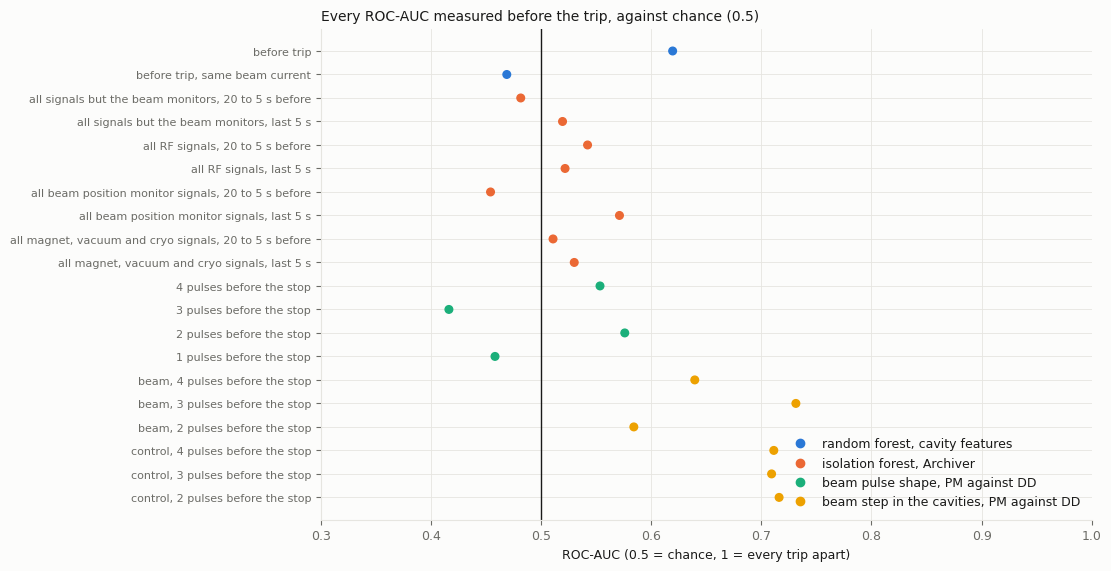

20 ROC-AUC values, from 0.42 to 0.73


In [2]:
forest = pd.read_parquet("ess_pm/random_forest.parquet").groupby("question", sort=False).auc.first()
model = pd.read_parquet("ess_archiver/pretrip_model.parquet")
shape_before = pd.read_parquet("ess_pm/beam_shape_before.parquet")
step_before = pd.read_parquet("ess_pm/beam_step_before.parquet").dropna(subset="roc_auc")
points = ([("random forest, cavity features", q, a) for q, a in forest.items() if q in ("before trip", "before trip, same beam current")]
          + [("isolation forest, Archiver", f"{r.signal_set}, {r.span}", r.auc) for r in model.itertuples() if r.span in ("20 to 5 s before", "last 5 s")]
          + [("beam pulse shape, PM against DD", f"{r.pulses_before_stop} pulses before the stop", r.roc_auc) for r in shape_before.itertuples()]
          + [("beam step in the cavities, PM against DD", f"{r.steps}, {r.pulses_before_stop} pulses before the stop", r.roc_auc) for r in step_before.itertuples()])
overview = pd.DataFrame(points, columns=["test", "case", "auc"])
fig, ax = plt.subplots(figsize=(11, 0.22 * len(overview) + 1.2), constrained_layout=True)
colors = dict(zip(overview.test.unique(), [BLUE, ORANGE, GREEN, COLOR["reflected"]]))
ax.scatter(overview.auc, range(len(overview)), c=overview.test.map(colors), s=30, zorder=3)
ax.axvline(0.5, color=INK, linewidth=1)
ax.set_yticks(range(len(overview)), overview.case, fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0.3, 1)
ax.set_xlabel("ROC-AUC (0.5 = chance, 1 = every trip apart)")
ax.legend([plt.Line2D([], [], marker="o", linestyle="", color=c) for c in colors.values()], colors.keys(), frameon=False, loc="lower right")
ax.set_title("Every ROC-AUC measured before the trip, against chance (0.5)")
plt.show()
print(f"{len(overview)} ROC-AUC values, from {overview.auc.min():.2f} to {overview.auc.max():.2f}")

## 1. Do the cavities leave their own band before an RF protection trip?

- **Looking for:** whether the cavities move away from their own earlier pulses in the last seconds before an RF protection trip, and whether the beam is still there when they do.
- **Data:** `ess_pm/cavity_pulses.parquet`, the 27 RF protection trips with a pulse within 1 s of the logged trip, columns `field_level`, `flat_std_rel`, `flat_tilt_rel`, `phase_mean_deg`, `fwd_flat`, `refl_flat`, `refl_ratio` of each cavity against its own pulses 6 s or more before (out = more than 8 spreads on any of them); `beam_level` of the same rows, read from the beam current monitors.
- **Says:** Median over the 27 trips, 5 to 7 cavities of 81 are out up to 3 pulses before the last, under the 99 % line of 10; at 2 pulses before, the beam level is already 0.05 (5.4 before) and 15 cavities are out, then 34 in the last two pulses.

In [3]:
mps = pd.read_parquet("ess_dd/mps_transitions.parquet")
PERMIT = "FBIS::beam_permit_ok"
trips = mps[(mps.pv == PERMIT) & (mps.value == 0)].data_ts.reset_index(drop=True)
drops = mps[(mps.pv != PERMIT) & (mps.value == 0)]


def trip_kind(t):
    """Which interlocks drop within a few seconds of the beam permit."""
    near = drops[(drops.data_ts >= t - pd.Timedelta("5s")) & (drops.data_ts <= t + pd.Timedelta("3s"))]
    systems = {pv.split("::")[-1].replace("-FBIS_ok", "") for pv in near.pv}
    if not systems:
        return "nothing else logged"
    if systems == {"RFLPS"}:
        return "RF protection"
    return "RF protection and beam" if "RFLPS" in systems else "beam instruments"


OWN = ["field_level", "flat_std_rel", "flat_tilt_rel", "phase_mean_deg", "fwd_flat", "refl_flat", "refl_ratio"]
pm = pd.read_parquet("ess_pm/cavity_pulses.parquet", columns=["event_id", "cavity", "cycle_rank_from_last", "seconds_to_next_trip", "has_pulse", "beam_level"] + OWN)
pm = pm[pm.has_pulse]
last = pm.groupby("event_id").seconds_to_next_trip.min()
pm = pm[pm.event_id.isin(last[last < 1].index)]
stamp = pd.read_parquet("ess_pm/cavity_pulses.parquet", columns=["event_id", "cycle_ts", "seconds_to_next_trip"])
stamp = stamp.loc[stamp.groupby("event_id").seconds_to_next_trip.idxmin()]
stamp["kind"] = [trip_kind(trips[(trips - (t + pd.Timedelta(seconds=x))).abs().idxmin()]) for t, x in zip(stamp.cycle_ts, stamp.seconds_to_next_trip)]
pm = pm.merge(stamp[["event_id", "kind"]], on="event_id")
pm["out"] = own_band_out(pm, OWN, ["event_id", "cavity"], pm[pm.cycle_rank_from_last >= 6])
rf = pm[(pm.kind == "RF protection") & (pm.cycle_rank_from_last <= 10)]
per_trip = rf.groupby(["cycle_rank_from_last", "event_id"]).agg(out=("out", "sum"), cavities=("out", "size"), beam=("beam_level", "median"))
by_second = per_trip.groupby("cycle_rank_from_last").agg(trips=("out", "size"), cavities_out=("out", "median"), cavities=("cavities", "median"), beam_level=("beam", "median"))
normal = pm[(pm.kind == "RF protection") & (pm.cycle_rank_from_last >= 6)].groupby(["cycle_rank_from_last", "event_id"]).out.sum()
print(f"99 % of the reference pulses (6 or more before the last) have at most {normal.quantile(0.99):.0f} cavities out")
by_second.sort_index(ascending=False).T.round(2)

99 % of the reference pulses (6 or more before the last) have at most 10 cavities out


cycle_rank_from_last,10,9,8,7,6,5,4,3,2,1,0
trips,27.00,27.0,27.00,27.00,27.00,27.00,27.00,27.00,27.00,27.00,27.00
cavities_out,5.00,5.0,6.00,6.00,5.00,6.00,6.00,7.00,15.00,34.00,34.00
cavities,81.00,81.0,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00,81.00
beam_level,5.41,5.4,5.42,5.41,5.38,5.39,5.38,5.35,0.05,0.05,0.05


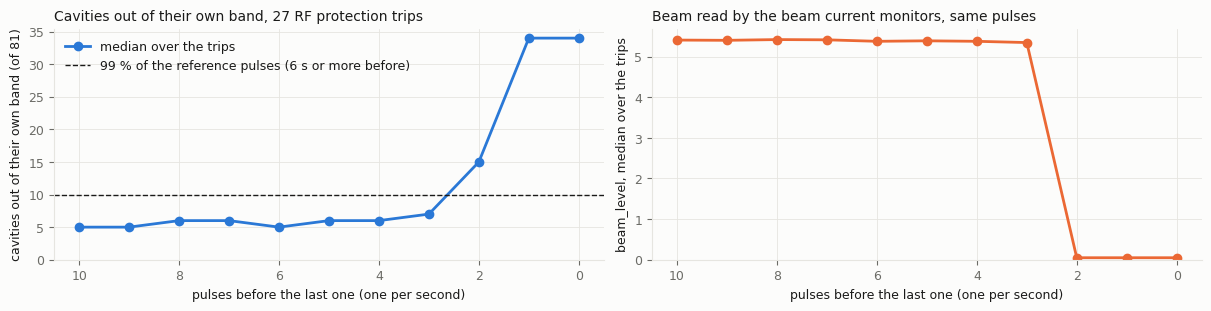

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3), constrained_layout=True)
left.plot(by_second.index, by_second.cavities_out, color=BLUE, linewidth=2, marker="o", label="median over the trips")
left.axhline(normal.quantile(0.99), color=INK, linewidth=1, linestyle="--", label="99 % of the reference pulses (6 s or more before)")
left.set_ylabel(f"cavities out of their own band (of {by_second.cavities.max():.0f})")
left.set_title(f"Cavities out of their own band, {rf.event_id.nunique()} RF protection trips")
left.legend(frameon=False)
right.plot(by_second.index, by_second.beam_level, color=ORANGE, linewidth=2, marker="o")
right.set_ylabel("beam_level, median over the trips")
right.set_title("Beam read by the beam current monitors, same pulses")
for ax in (left, right):
    ax.invert_xaxis()
    ax.set_xlabel("pulses before the last one (one per second)")
    ax.set_ylim(bottom=0)
plt.show()

## 2. Are the pulses before a trip further from normal than normal pulses?

- **Looking for:** whether PM pulses before a trip sit outside the band of nominal DD pulses more often than a nominal capture does against the other nominal captures.
- **Data:** `ess_pm/cavity_pulses.parquet` against `ess_dd/cavity_pulses.parquet`, pulses with an RF pulse on the days that hold both, full-length records, same `cavity`, `beam_present`, `beam_mode`, `beam_current`; 23 shape features (the non-drift features of `ess_dd_features.py`); off = 3 or more features outside the 0.5 to 99.5 % band of at least 30 nominal pulses.
- **Says:** 6 s or more before the trip 12.9 % of trip pulses are off the nominal band, against 21.6 % for a nominal capture against the others (0 of 14 against 3 of 26 captures over 50 %); at the last pulse 70.8 %, with 8 of 12 captures over 50 %.

In [5]:
SETTING = ["cavity", "beam_present", "beam_mode", "beam_current"]
SHAPE = ["flat_len", "pulse_len", "flat_std_rel", "flat_step_max_rel", "flat_p2p_rel", "flat_max_dev_rel", "flat_tilt_rel", "field_level",
         "rise_len", "fall_len", "decay_tau", "field_end_after_rf_off", "phase_mean_deg", "phase_std_deg", "phase_p2p_deg", "phase_tilt_deg",
         "fwd_flat", "fwd_flat_std_rel", "fwd_peak", "refl_flat", "refl_fill_peak", "refl_end_peak", "refl_ratio"]
columns = ["event_id", "capture_window", "has_pulse", "array_size", "cycle_rank_from_last", "seconds_to_next_trip"] + SETTING + SHAPE
trip_pulses, dd = pd.read_parquet("ess_pm/cavity_pulses.parquet", columns=columns), pd.read_parquet("ess_dd/cavity_pulses.parquet", columns=columns)
days = set(trip_pulses.capture_window) & set(dd.capture_window)
usable = lambda t: t[t.has_pulse & t.capture_window.isin(days) & (t.array_size == dd.array_size.max())]
trip_pulses, nominal = usable(trip_pulses), usable(dd)
nominal = nominal[~(nominal.seconds_to_next_trip < 1)]


def off(test, reference):
    """Whether each test pulse is outside the reference band on 3 or more features; needs 30 reference pulses."""
    band = reference.groupby(SETTING)[SHAPE]
    low, high, count = band.quantile(0.005), band.quantile(0.995), band.size()
    rows = pd.MultiIndex.from_frame(test[SETTING])
    outside = (test[SHAPE].to_numpy() < low.reindex(rows).to_numpy()) | (test[SHAPE].to_numpy() > high.reindex(rows).to_numpy())
    return pd.Series(outside.sum(axis=1) >= 3, index=test.index)[count.reindex(rows).fillna(0).to_numpy() >= 30]


held_out = pd.concat([off(x, nominal[nominal.event_id != e]) for e, x in nominal.groupby("event_id")])
against = off(trip_pulses, nominal)
rank = trip_pulses.cycle_rank_from_last.reindex(against.index)
groups = {"nominal capture,\nagainst the other nominal ones": (held_out, nominal), "trip capture,\n6 s or more before": (against[rank >= 6], trip_pulses),
          "trip capture,\nlast pulse": (against[rank == 0], trip_pulses)}
share = {name: 100 * flags.groupby(of.event_id.reindex(flags.index)).mean() for name, (flags, of) in groups.items()}
pd.DataFrame({name.replace("\n", " "): {"captures": len(s), "pulses off, %": round(100 * groups[name][0].mean(), 1), "captures with most cavities off": int((s > 50).sum())}
              for name, s in share.items()}).T

,captures,"pulses off, %",captures with most cavities off
"nominal capture, against the other nominal ones",26.0,21.6,3.0
"trip capture, 6 s or more before",14.0,12.9,0.0
"trip capture, last pulse",12.0,70.8,8.0


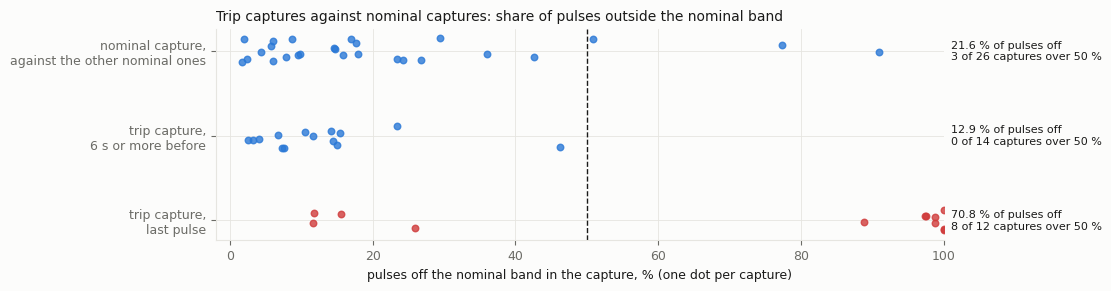

In [6]:
fig, ax = plt.subplots(figsize=(11, 2.8), constrained_layout=True)
for i, (name, s) in enumerate(share.items()):
    ax.scatter(s, i + rng.uniform(-0.15, 0.15, len(s)), s=22, color=CRITICAL if "last" in name else BLUE, alpha=0.8)
    ax.text(101, i, f"{100 * groups[name][0].mean():.1f} % of pulses off\n{(s > 50).sum()} of {len(s)} captures over 50 %", va="center", fontsize=8)
ax.axvline(50, color=INK, linewidth=1, linestyle="--")
ax.set_yticks(range(len(share)), share.keys())
ax.invert_yaxis()
ax.set_xlim(-2, 100)
ax.set_xlabel("pulses off the nominal band in the capture, % (one dot per capture)")
ax.set_title("Trip captures against nominal captures: share of pulses outside the nominal band")
plt.show()

## 3. Can a random forest tell trip captures from nominal ones?

- **Looking for:** whether a forest on the cavity features, scored on captures it has not seen, separates PM captures from DD captures before the trip, and whether that survives at the same beam current.
- **Data:** `ess_pm/random_forest.parquet`, columns `question`, `auc`, `positive_captures`, `negative_captures` (one AUC per question; the features are the distances of `ess_pm/cavity_pulses.parquet` and `ess_dd/cavity_pulses.parquet` to their level 6 to 12 s before the end).
- **Says:** ROC-AUC 0.62 at 3 to 5 s before the trip (23 against 28 captures) and 0.47 when both sides run at the same beam current (5 against 9), where beam current alone gives 0.73 and the control 0.47.

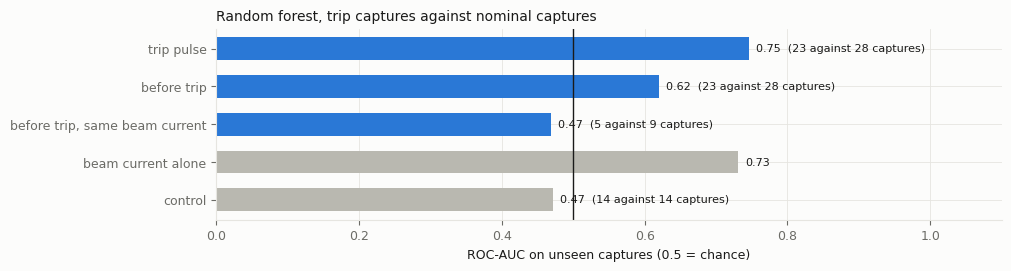

In [7]:
forest = pd.read_parquet("ess_pm/random_forest.parquet").groupby("question", sort=False).first()
fig, ax = plt.subplots(figsize=(10, 2.6), constrained_layout=True)
ax.barh(range(len(forest)), forest.auc, height=0.6, color=[GREY if q in ("control", "beam current alone") else BLUE for q in forest.index])
for i, r in enumerate(forest.itertuples()):
    sides = "" if np.isnan(r.positive_captures) else f"  ({r.positive_captures:.0f} against {r.negative_captures:.0f} captures)"
    ax.text(r.auc + 0.01, i, f"{r.auc:.2f}{sides}", va="center", fontsize=8)
ax.axvline(0.5, color=INK, linewidth=1)
ax.set_yticks(range(len(forest)), forest.index)
ax.invert_yaxis()
ax.set_xlim(0, 1.1)
ax.set_xlabel("ROC-AUC on unseen captures (0.5 = chance)")
ax.set_title("Random forest, trip captures against nominal captures")
plt.show()

## 4. Does an autoencoder find the cut pulse better than the features?

- **Looking for:** whether the reconstruction error of a convolutional autoencoder sets the cut pulse further from normal than the feature `shape_drift`, on one cavity.
- **Data:** `ess_dd_one_cavity/ae_errors.parquet` column `recon_mse` (every pulse scored by a network that never saw its capture) and `ess_dd_one_cavity/one_cavity_pulses.parquet` columns `shape_drift`, `flat_len`, `beam_current`: the 311 pulses with beam of `MBL-090RFC:RFS-DIG-101`; cut = `flat_len` under 90 % of its median; before trip = `seconds_to_next_trip` under 1 from `ess_dd/cavity_pulses.parquet`.
- **Says:** Both rank the cut pulse first, 1,138 times the worst normal pulse for the autoencoder and 2,065 times for `shape_drift`; the three whole last pulses before a trip sit among the other pulses on both, and the autoencoder error is higher at beam current 62,000 than at 4,000 to 5,000 (Spearman r 0.16, against -0.05 for `shape_drift`).

In [8]:
one = pd.read_parquet("ess_dd_one_cavity/one_cavity_pulses.parquet", columns=["event_id", "cycle_id", "cavity", "flat_len", "shape_drift", "beam_current"])
one = one.merge(pd.read_parquet("ess_dd/cavity_pulses.parquet", columns=["event_id", "cycle_id", "cavity", "seconds_to_next_trip"]), on=["event_id", "cycle_id", "cavity"], validate="one_to_one")
ae = pd.read_parquet("ess_dd_one_cavity/ae_errors.parquet").merge(one, on=["event_id", "cycle_id", "cavity"], validate="one_to_one")
ae["is_cut"] = ae.flat_len < 0.9 * ae.flat_len.median()
ae["before_trip"] = (ae.seconds_to_next_trip < 1) & ~ae.is_cut
normal = ae[~ae.is_cut]
pd.DataFrame({name: {"rank of the cut pulse": int(ae[c].rank(ascending=False)[ae.is_cut].iloc[0]),
                     "cut pulse over the worst normal pulse": round(float(ae[c][ae.is_cut].iloc[0] / normal[c].max())),
                     "worst normal pulse over the median": round(float(normal[c].max() / normal[c].median()), 1),
                     "Spearman r with beam current": round(float(stats.spearmanr(normal[c], normal.beam_current)[0]), 2)}
              for name, c in [("autoencoder error", "recon_mse"), ("shape_drift", "shape_drift")]})

,autoencoder error,shape_drift
rank of the cut pulse,1.00,1.00
cut pulse over the worst normal pulse,1138.00,2065.00
worst normal pulse over the median,22.10,6.00
Spearman r with beam current,0.16,-0.05


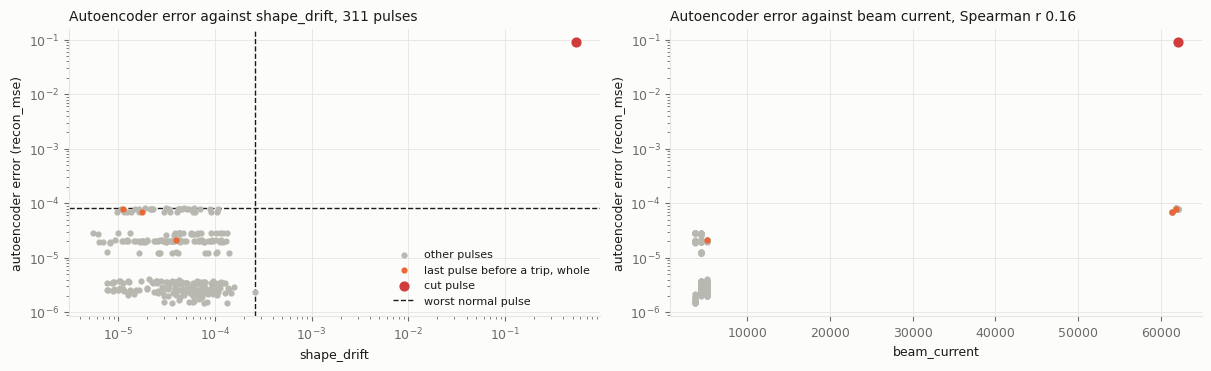

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
for mask, color, label in [(~ae.is_cut & ~ae.before_trip, GREY, "other pulses"), (ae.before_trip, ORANGE, "last pulse before a trip, whole"), (ae.is_cut, CRITICAL, "cut pulse")]:
    left.scatter(ae.shape_drift[mask], ae.recon_mse[mask], s=40 if color == CRITICAL else 12, color=color, label=label, zorder=3)
    right.scatter(ae.beam_current[mask], ae.recon_mse[mask], s=40 if color == CRITICAL else 12, color=color, zorder=3)
left.axvline(normal.shape_drift.max(), color=INK, linewidth=1, linestyle="--")
left.axhline(normal.recon_mse.max(), color=INK, linewidth=1, linestyle="--", label="worst normal pulse")
left.set(xscale="log", yscale="log", xlabel="shape_drift", ylabel="autoencoder error (recon_mse)")
left.set_title("Autoencoder error against shape_drift, 311 pulses")
left.legend(frameon=False, fontsize=8)
right.set(yscale="log", xlabel="beam_current", ylabel="autoencoder error (recon_mse)")
right.set_title(f"Autoencoder error against beam current, Spearman r {stats.spearmanr(normal.recon_mse, normal.beam_current)[0]:.2f}")
plt.show()

## 5. Do the beam current monitors move before the trip?

- **Looking for:** whether the beam pulse read by each beam current monitor leaves its own earlier band in the pulses before the last one with beam.
- **Data:** `ess_pm/beam_pulses.parquet`, the 52 trip captures of section 1, rows with `has_beam`, columns `beam_level`, `beam_len_us`, `beam_start_us`, `beam_flat_std_rel`, `beam_charge` of each `device` against its own pulses 6 or more before the last pulse with beam (out = more than 8 spreads on any of them, 5 reference pulses needed).
- **Says:** 0.4 to 3.1 % of the readings are out from 10 to 3 pulses before the last pulse with beam, against 1.9 % for the reference pulses; 5.6 % at 2 and 1 pulses before, 14.9 % in the last pulse with beam (44 trips).

In [10]:
beam = pd.read_parquet("ess_pm/beam_pulses.parquet")
beam = beam[beam.event_id.isin(pm.event_id.unique())]
cycles = beam.groupby(["event_id", "cycle_id"]).agg(monitors=("device", "size"), with_beam=("has_beam", "sum")).reset_index().sort_values(["event_id", "cycle_id"])
cycles["from_end"] = cycles.groupby("event_id").cumcount(ascending=False)
last_beam = cycles[cycles.with_beam >= cycles.monitors / 2].groupby("event_id").from_end.min().rename("last_beam")
cycles = cycles.merge(last_beam, on="event_id")
cycles["before_last_beam"] = cycles.from_end - cycles.last_beam
beam = beam[beam.has_beam].merge(cycles[["event_id", "cycle_id", "before_last_beam"]], on=["event_id", "cycle_id"]).query("before_last_beam >= 0")
BEAM = ["beam_level", "beam_len_us", "beam_start_us", "beam_flat_std_rel", "beam_charge"]
earlier = beam[beam.before_last_beam >= 6]
beam["out"] = own_band_out(beam, BEAM, ["event_id", "device"], earlier)
beam = beam[earlier.groupby(["event_id", "device"]).size().reindex(pd.MultiIndex.from_frame(beam[["event_id", "device"]])).fillna(0).to_numpy() >= 5]
per_pulse = beam[beam.before_last_beam <= 10].groupby("before_last_beam").agg(trips=("event_id", "nunique"), readings_out=("out", "mean"))
print(f"reference pulses (6 or more before the last with beam): {100 * beam.out[beam.before_last_beam >= 6].mean():.1f} % of readings out")
(100 * per_pulse.readings_out).round(1).rename("readings out, %").to_frame().join(per_pulse.trips).sort_index(ascending=False).T

reference pulses (6 or more before the last with beam): 1.9 % of readings out


before_last_beam,10,9,8,7,6,5,4,3,2,1,0
"readings out, %",1.5,0.4,3.1,0.8,0.6,3.1,1.5,1.5,5.6,5.6,14.9
trips,44.0,44.0,44.0,44.0,44.0,44.0,44.0,44.0,44.0,44.0,44.0


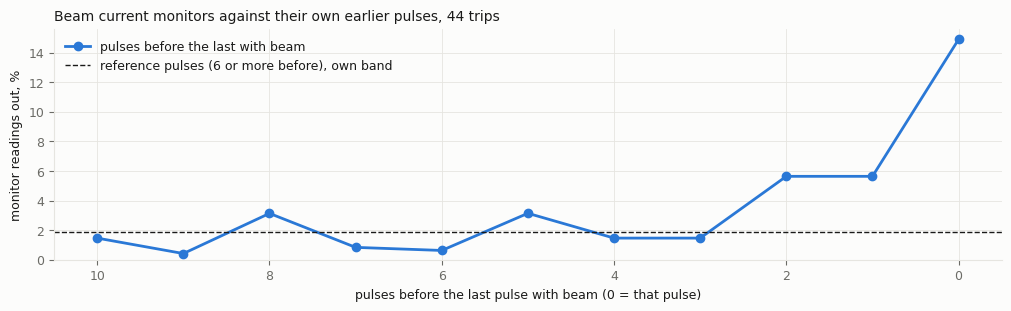

In [11]:
fig, ax = plt.subplots(figsize=(10, 3), constrained_layout=True)
ax.plot(per_pulse.index, 100 * per_pulse.readings_out, color=BLUE, linewidth=2, marker="o", label="pulses before the last with beam")
ax.axhline(100 * beam.out[beam.before_last_beam >= 6].mean(), color=INK, linewidth=1, linestyle="--", label="reference pulses (6 or more before), own band")
ax.invert_xaxis()
ax.set_ylim(bottom=0)
ax.set_xlabel("pulses before the last pulse with beam (0 = that pulse)")
ax.set_ylabel("monitor readings out, %")
ax.set_title(f"Beam current monitors against their own earlier pulses, {per_pulse.trips.max()} trips")
ax.legend(frameon=False)
plt.show()

## 6. Do the RF signals of the Archiver move before the trip?

- **Looking for:** whether more RF signals leave their own earlier level at a trip than at a quiet moment of the same run and beam current, before and after the beam stops.
- **Data:** `ess_archiver/pretrip_events.parquet`, rows with `referenced`: 47 trips and 17,163 quiet moments, columns `<span> | all RF signals` (count of the 192 RF signals out) and the six RF groups; flag limit = column `limit` of `ess_archiver/pretrip_summary.parquet` (99 % of the quiet moments). Chance = quiet moments over the limit times 47; p = binomial tail.
- **Says:** All RF signals: 0 of 47 trips flagged 20 to 5 s before and 0 in the last 5 s (chance 0.4 and 0.3); 23 of 47 1 to 3 s after (p 1e-34), carried by the front end RF level (27 of 47); modulator voltage and klystron current 0 of 47 in every span but 1 klystron trip in the second of the trip.

47 trips, 17163 quiet moments


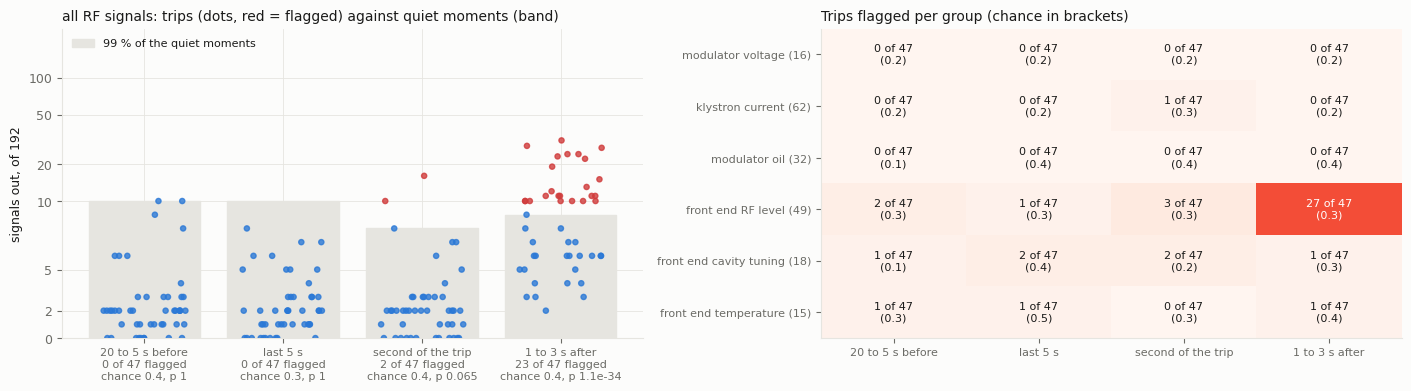

trips flagged before the beam stops: none


In [12]:
events = pd.read_parquet("ess_archiver/pretrip_events.parquet").query("referenced")
summary = pd.read_parquet("ess_archiver/pretrip_summary.parquet")
SPANS = ["20 to 5 s before", "last 5 s", "second of the trip", "1 to 3 s after"]


def strip(ax, events, summary, group, spans):
    """Signals out at each trip (dots, red when flagged) against the 99 % line of the quiet moments."""
    quiet, trip = events[~events.is_trip], events[events.is_trip]
    signals = summary[summary.group == group].signals.iloc[0]
    labels, before = [], []
    for i, span in enumerate(spans):
        col = f"{span} | {group}"
        limit = summary[(summary.group == group) & (summary.span == span)].limit.iloc[0]
        rate, flagged = (quiet[col] > limit).mean(), trip[col] > limit
        ax.fill_between([i - 0.4, i + 0.4], 0, limit, color=GRID, label="99 % of the quiet moments" if i == 0 else None)
        ax.scatter(i + rng.uniform(-0.3, 0.3, len(trip)), trip[col], s=14, c=np.where(flagged, CRITICAL, BLUE), alpha=0.8, zorder=3)
        labels.append(f"{span}\n{flagged.sum()} of {len(trip)} flagged\nchance {rate * len(trip):.1f}, p {stats.binom.sf(flagged.sum() - 1, len(trip), rate):.2g}")
        if "before" in span or "last" in span:
            before.append(trip.loc[flagged, ["time", "kind"]].assign(group=group, span=span, signals_out=trip[col][flagged], limit=limit))
    ticks = [t for t in [0, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000] if t <= signals]
    ax.set_yscale("symlog", linthresh=10)
    ax.set_yticks(ticks, [str(t) for t in ticks])
    ax.set_ylim(0, 1.3 * signals)
    ax.set_xticks(range(len(spans)), labels, fontsize=8)
    ax.set_ylabel(f"signals out, of {signals}")
    ax.set_title(f"{group}: trips (dots, red = flagged) against quiet moments (band)")
    ax.legend(frameon=False, loc="upper left", fontsize=8)
    return pd.concat(before)


def show_flagged(flagged):
    print("trips flagged before the beam stops:", "none" if flagged.empty else "\n" + flagged.to_string(index=False))


def flag_grid(ax, summary, groups, spans):
    """Trips flagged per group and span, with what the quiet moments give by chance in brackets."""
    at = summary[summary.kind != "quiet moment"].groupby(["group", "span"])[["flagged", "events"]].sum()
    quiet = summary[summary.kind == "quiet moment"].set_index(["group", "span"])
    k = at.flagged.unstack()[spans].loc[groups]
    chance = (quiet.flagged / quiet.events * at.events).unstack()[spans].loc[groups]
    n = at.events.iloc[0]
    ax.imshow(k.to_numpy(), cmap="Reds", vmin=0, vmax=n, aspect="auto")
    for (r, c), v in np.ndenumerate(k.to_numpy()):
        ax.text(c, r, f"{v} of {n}\n({chance.iat[r, c]:.1f})", ha="center", va="center", fontsize=8, color="white" if v > n / 2 else INK)
    ax.set_xticks(range(len(spans)), spans, fontsize=8)
    ax.set_yticks(range(len(groups)), [f"{g} ({summary[summary.group == g].signals.iloc[0]})" for g in groups], fontsize=8)
    ax.grid(False)
    ax.set_title("Trips flagged per group (chance in brackets)")


print(f"{events.is_trip.sum()} trips, {(~events.is_trip).sum()} quiet moments")
RF_GROUPS = ["modulator voltage", "klystron current", "modulator oil", "front end RF level", "front end cavity tuning", "front end temperature"]
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 3.8), constrained_layout=True)
flagged = strip(left, events, summary, "all RF signals", SPANS)
flag_grid(right, summary, RF_GROUPS, SPANS)
plt.show()
show_flagged(flagged)

## 7. Do the beam position monitors of the Archiver move before the trip?

- **Looking for:** whether more beam position monitor signals leave their own earlier level at a trip than at a quiet moment, one value per beam pulse.
- **Data:** `ess_archiver/pretrip_events.parquet` (47 trips, 17,163 quiet moments), columns `<span> | all beam position monitor signals` (340 signals of 85 monitors) and `beam position`, `beam phase`, `beam signal strength`; limit from `ess_archiver/pretrip_summary.parquet`.
- **Says:** 1 of 47 trips flagged 20 to 5 s before (chance 0.5, p 0.38) and 3 of 47 in the last 5 s (chance 0.5, p 0.011): 98 signals out against a limit of 70, and two trips (2026-06-28 20:10:49 and 2026-06-29 20:13:54) with 305 and 306 of 340 out; 24 of 47 in the second of the trip.

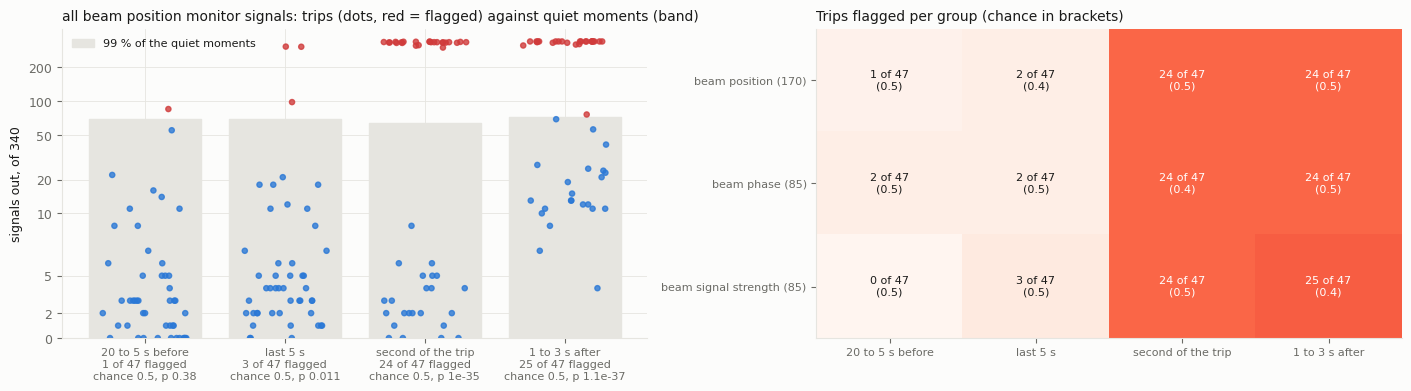

trips flagged before the beam stops: 
                               time                   kind                             group             span  signals_out  limit
2025-05-29 12:28:15.832928446+00:00          RF protection all beam position monitor signals 20 to 5 s before           85  69.38
2025-05-29 10:11:09.833305811+00:00          RF protection all beam position monitor signals         last 5 s           98  70.00
2026-06-28 20:10:49.060446335+00:00       beam instruments all beam position monitor signals         last 5 s          305  70.00
2026-06-29 20:13:54.056474319+00:00 RF protection and beam all beam position monitor signals         last 5 s          306  70.00


In [13]:
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 3.8), constrained_layout=True)
flagged = strip(left, events, summary, "all beam position monitor signals", SPANS)
flag_grid(right, summary, ["beam position", "beam phase", "beam signal strength"], SPANS)
plt.show()
show_flagged(flagged)

## 8. Do the magnets, the vacuum or the cryogenics move before the trip?

- **Looking for:** whether more magnet, vacuum and cryo signals leave their own earlier level at a trip than at a quiet moment.
- **Data:** `ess_archiver/pretrip_events.parquet` (47 trips, 17,163 quiet moments), columns `<span> | all magnet, vacuum and cryo signals` (1,689 signals) and the five groups; limit from `ess_archiver/pretrip_summary.parquet`; the flagged trip's signals from `ess_archiver/pretrip_signals.parquet` (`out`, `pv`).
- **Says:** 0 of 47 trips flagged 20 to 5 s before and 1 of 47 in the last 5 s, in the second of the trip and after (chance 0.5 each); it is the same trip each time, 2025-05-30 00:50:45 UTC, with 53, 75, 95 and 96 DC link voltages of the magnet power supplies out over the four spans.

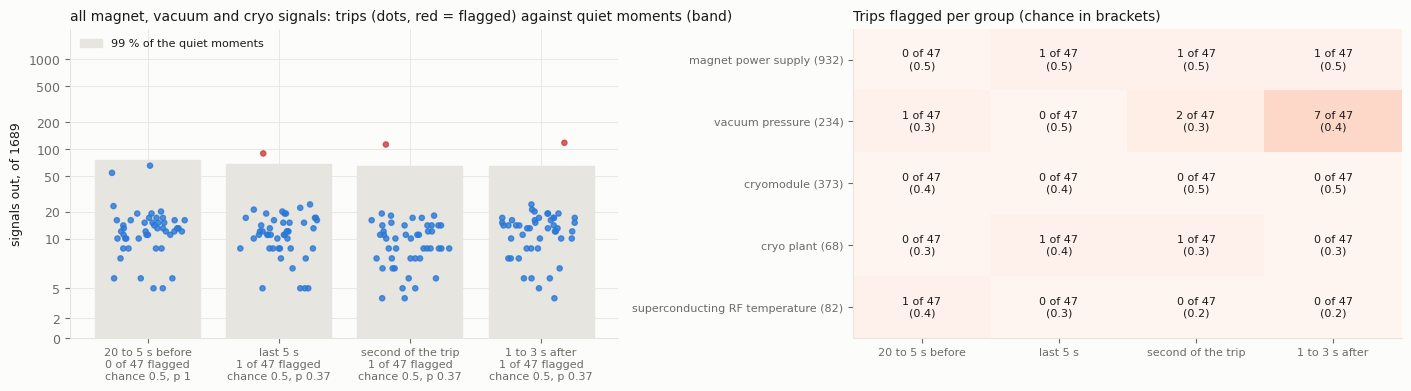

trips flagged before the beam stops: 
                               time          kind                               group     span  signals_out  limit
2025-05-30 00:50:45.830884756+00:00 RF protection all magnet, vacuum and cryo signals last 5 s           89   67.0


In [14]:
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 3.8), constrained_layout=True)
flagged = strip(left, events, summary, "all magnet, vacuum and cryo signals", SPANS)
flag_grid(right, summary, ["magnet power supply", "vacuum pressure", "cryomodule", "cryo plant", "superconducting RF temperature"], SPANS)
plt.show()
show_flagged(flagged)

In [15]:
signals = pd.read_parquet("ess_archiver/pretrip_signals.parquet")
magnets = signals[(signals.group == "magnet power supply") & signals.out]
flagged_trip = magnets.groupby("time").size().idxmax()
dc_link = magnets[(magnets.time == flagged_trip) & magnets.pv.str.contains("DCLnkVol")]
print(f"trip with the most magnet power supply signals out: {flagged_trip:%Y-%m-%d %H:%M:%S} UTC")
dc_link.groupby("span").pv.nunique().reindex(SPANS).fillna(0).astype(int).rename("DC link voltages out").to_frame().T

trip with the most magnet power supply signals out: 2025-05-30 00:50:45 UTC


span,20 to 5 s before,last 5 s,second of the trip,1 to 3 s after
DC link voltages out,53,75,95,96


## 9. Does the beam transmission move before the trip?

- **Looking for:** whether the share of the beam reaching each beam current monitor leaves its own earlier level at a trip more than at a quiet moment.
- **Data:** `ess_archiver/pretrip_events.parquet` (47 trips, 17,163 quiet moments), columns `<span> | beam transmission` (12 signals: each beam current monitor over the first MEBT one) and `<span> | beam current`; limit from `ess_archiver/pretrip_summary.parquet`.
- **Says:** Beam transmission: 1 of 47 trips flagged 20 to 5 s before (chance 0.3, p 0.28) and 3 of 47 in the last 5 s (chance 0.4, p 0.01), two of them the same 2026-06-28 20:10 and 2026-06-29 20:13 trips as in section 7; the beam current is flagged in 47 of 47 from the second of the trip.

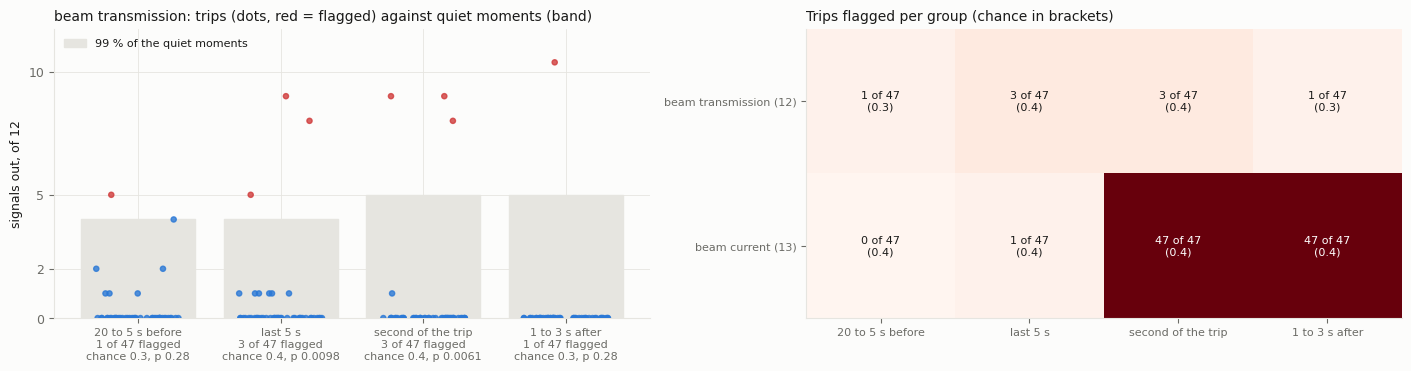

trips flagged before the beam stops: 
                               time                   kind             group             span  signals_out  limit
2025-05-30 03:40:05.830418670+00:00          RF protection beam transmission 20 to 5 s before            5    4.0
2026-06-07 06:48:45.710450901+00:00       beam instruments beam transmission         last 5 s            5    4.0
2026-06-28 20:10:49.060446335+00:00       beam instruments beam transmission         last 5 s            8    4.0
2026-06-29 20:13:54.056474319+00:00 RF protection and beam beam transmission         last 5 s            9    4.0


In [16]:
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 3.6), constrained_layout=True)
flagged = strip(left, events, summary, "beam transmission", SPANS)
flag_grid(right, summary, ["beam transmission", "beam current"], SPANS)
plt.show()
show_flagged(flagged)

## 10. Does a model on all the signals at once see the trip coming?

- **Looking for:** whether an isolation forest fitted on quiet moments scores trips as more unusual than quiet moments of other runs, per span.
- **Data:** `ess_archiver/pretrip_model.parquet`, columns `signal_set`, `span`, `auc`, `trips_above_99` (47 trips; fitted on the quiet moments of some runs, scored on the others).
- **Says:** ROC-AUC 0.45 to 0.54 at 20 to 5 s before and 0.52 to 0.57 in the last 5 s for every signal set; 1 to 3 s after it is 0.91 on the RF signals and on the beam position monitors.

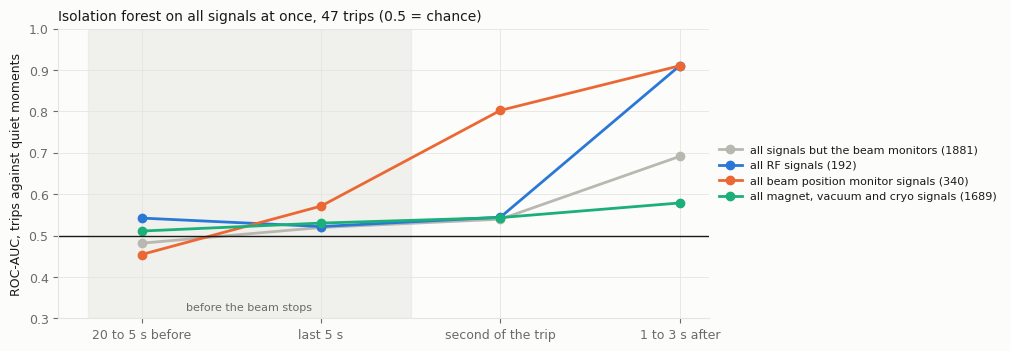

,20 to 5 s before,last 5 s,second of the trip,1 to 3 s after
trips above 99 % of quiet moments,,,,
all RF signals,0,0,2,13
all beam position monitor signals,1,3,24,24
"all magnet, vacuum and cryo signals",0,1,1,1
all signals but the beam monitors,0,1,1,1


In [17]:
model = pd.read_parquet("ess_archiver/pretrip_model.parquet")
fig, ax = plt.subplots(figsize=(10, 3.4), constrained_layout=True)
for (name, rows), color in zip(model.groupby("signal_set", sort=False), [GREY, BLUE, ORANGE, GREEN]):
    rows = rows.set_index("span").loc[SPANS]
    ax.plot(range(len(SPANS)), rows.auc, marker="o", linewidth=2, color=color, label=f"{name} ({rows.signals.iloc[0]})")
ax.axhline(0.5, color=INK, linewidth=1)
ax.axvspan(-0.3, 1.5, color=GRID, alpha=0.5, zorder=0)
ax.text(0.6, 0.32, "before the beam stops", ha="center", fontsize=8, color=MUTED)
ax.set_xticks(range(len(SPANS)), SPANS)
ax.set_ylim(0.3, 1)
ax.set_ylabel("ROC-AUC, trips against quiet moments")
ax.set_title("Isolation forest on all signals at once, 47 trips (0.5 = chance)")
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()
model.pivot(index="signal_set", columns="span", values="trips_above_99")[SPANS].rename_axis(index="trips above 99 % of quiet moments", columns=None)

## 11. At high beam current, with short windows, does anything move before the trip?

- **Looking for:** the same count of signals out as in sections 6 to 9, inside the afternoon of high beam current, with each signal against its level 40 to 10 s earlier.
- **Data:** `ess_archiver_short/pretrip_events.parquet`, rows with `referenced`: 14 trips with a beam current reading above 10 and 3,369 quiet moments of the same afternoon, columns `<span> | <group>` for the four groups; limit from `ess_archiver_short/pretrip_summary.parquet`.
- **Says:** Before the trip RF signals flag 1 of 14 at 10 to 3 s (2026-06-29 18:13:55, 10 signals against a limit of 9), beam position monitors and transmission 1 of 14 in the last 3 s (2026-06-29 20:13:54), magnets, vacuum and cryo 0 of 14; chance is 0.1 per span; 1 to 3 s after, RF flags 11 of 14.

14 trips, 3369 quiet moments


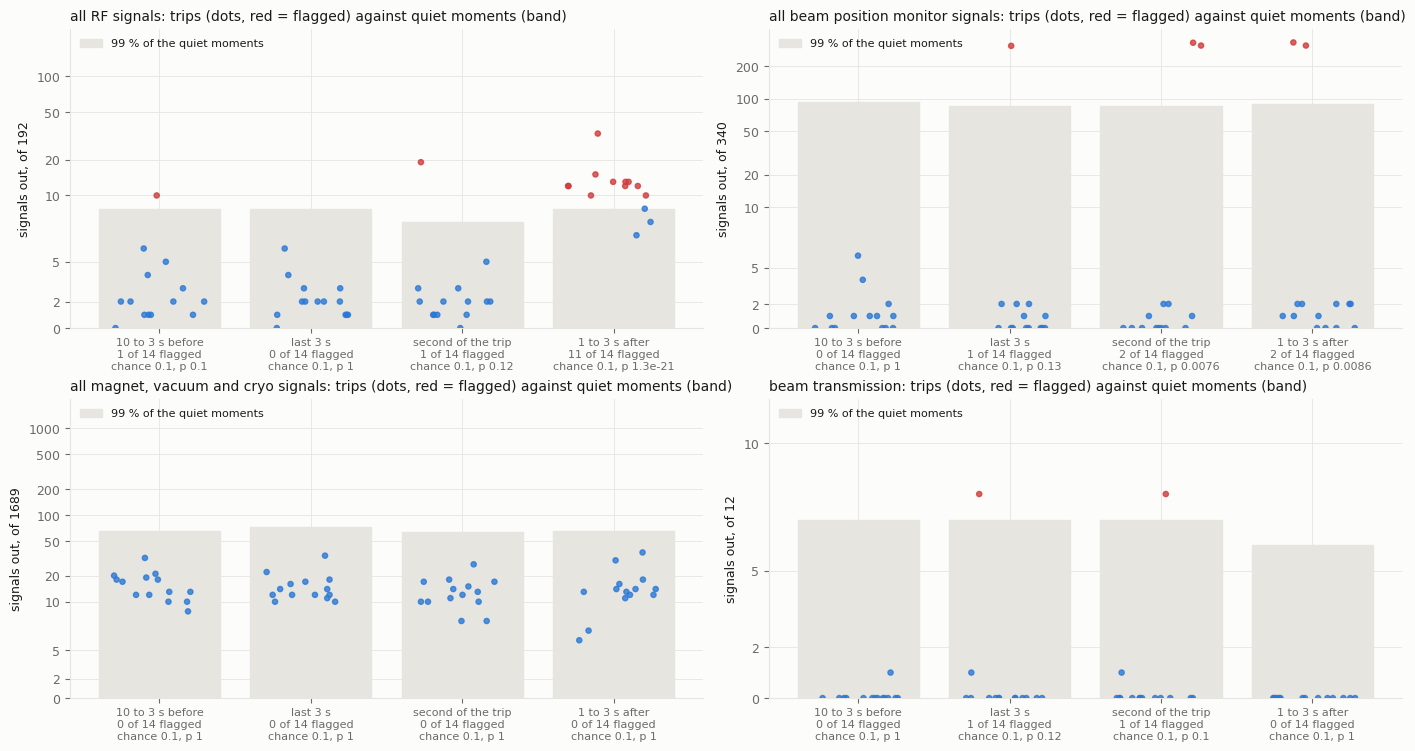

trips flagged before the beam stops: 
                               time                   kind                             group             span  signals_out  limit
2026-06-29 18:13:55.056804565+00:00 RF protection and beam                    all RF signals 10 to 3 s before           10   9.00
2026-06-29 20:13:54.056474319+00:00 RF protection and beam all beam position monitor signals         last 3 s          307  86.32
2026-06-29 20:13:54.056474319+00:00 RF protection and beam                 beam transmission         last 3 s            8   7.00


In [18]:
short = pd.read_parquet("ess_archiver_short/pretrip_events.parquet").query("referenced")
short_summary = pd.read_parquet("ess_archiver_short/pretrip_summary.parquet")
SHORT = ["10 to 3 s before", "last 3 s", "second of the trip", "1 to 3 s after"]
print(f"{short.is_trip.sum()} trips, {(~short.is_trip).sum()} quiet moments")
fig, axes = plt.subplots(2, 2, figsize=(14, 7.4), constrained_layout=True)
flagged = pd.concat([strip(ax, short, short_summary, group, SHORT) for ax, group in
                     zip(axes.flat, ["all RF signals", "all beam position monitor signals", "all magnet, vacuum and cryo signals", "beam transmission"])])
plt.show()
show_flagged(flagged)

## 12. Is any signal at an unusual level before the trips?

- **Looking for:** whether some Archiver signal sits higher or lower 10 to 3 s before a trip than at moments of other beam stretches that held, at the same beam current and as long after the beam came back.
- **Data:** `ess_archiver/trip_levels.parquet`, column `z` of 2,233 signals per regime, and `ess_archiver/trip_levels_trips.parquet`, columns `trips_compared`, `signals_beyond_z3`, `mock_signals_beyond_z3`, `furthest_z`, `mock_furthest_z_median`, `mock_furthest_z_95` (200 mock draws: each trip replaced by a moment that held).
- **Says:** Under 10, 33 trips: 13 signals beyond z 3 where mock trips give 13.2, furthest 3.6 where mock trips reach 3.6 (median) and 4.5 (95 %); over 40, 6 trips: 6 signals against 37.5, furthest 3.5 against 3.8 and 4.2.

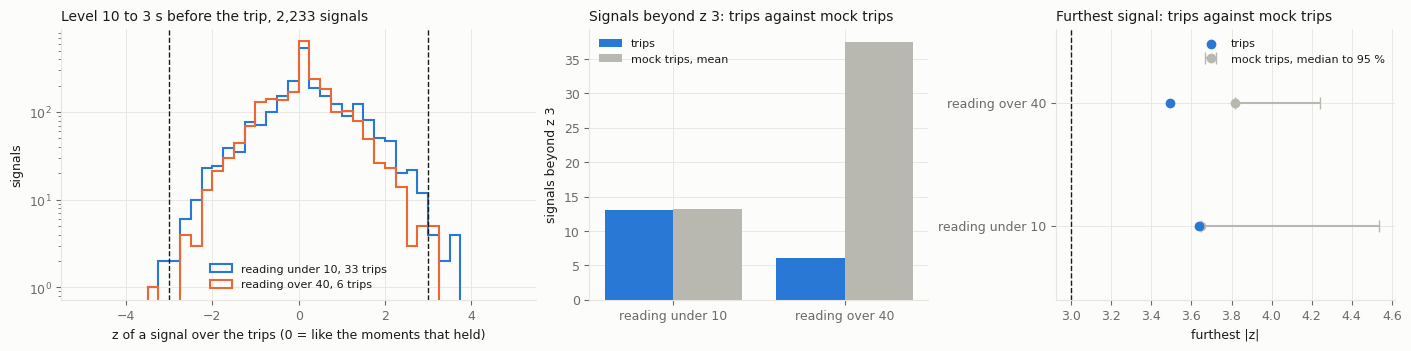

In [19]:
levels = pd.read_parquet("ess_archiver/trip_levels.parquet")
regimes = pd.read_parquet("ess_archiver/trip_levels_trips.parquet").set_index("regime")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), constrained_layout=True, width_ratios=[1.4, 1, 1])
for regime, color in zip(regimes.index, [BLUE, ORANGE]):
    axes[0].hist(levels.z[levels.regime == regime], bins=np.arange(-5, 5.01, 0.25), histtype="step", linewidth=1.5, color=color,
                 label=f"{regime}, {regimes.trips_compared[regime]} trips")
for ax in axes[0], axes[2]:
    ax.axvline(3, color=INK, linewidth=1, linestyle="--")
axes[0].axvline(-3, color=INK, linewidth=1, linestyle="--")
axes[0].set(yscale="log", xlabel="z of a signal over the trips (0 = like the moments that held)", ylabel="signals")
axes[0].set_title("Level 10 to 3 s before the trip, 2,233 signals")
axes[0].legend(frameon=False, fontsize=8)
x = np.arange(len(regimes))
axes[1].bar(x - 0.2, regimes.signals_beyond_z3, 0.4, color=BLUE, label="trips")
axes[1].bar(x + 0.2, regimes.mock_signals_beyond_z3, 0.4, color=GREY, label="mock trips, mean")
axes[1].set_xticks(x, regimes.index)
axes[1].set_ylabel("signals beyond z 3")
axes[1].set_title("Signals beyond z 3: trips against mock trips")
axes[1].legend(frameon=False, fontsize=8)
axes[2].errorbar(regimes.mock_furthest_z_median, x, xerr=[np.zeros(len(x)), regimes.mock_furthest_z_95 - regimes.mock_furthest_z_median],
                 fmt="o", color=GREY, capsize=4, label="mock trips, median to 95 %")
axes[2].scatter(regimes.furthest_z, x, color=BLUE, zorder=3, label="trips")
axes[2].set_yticks(x, regimes.index)
axes[2].set_ylim(-0.6, 1.6)
axes[2].set_xlabel("furthest |z|")
axes[2].set_title("Furthest signal: trips against mock trips")
axes[2].legend(frameon=False, fontsize=8)
plt.show()

## 13. Does the beam move inside its last pulses (2025 waveforms)?

- **Looking for:** whether the beam position, phase and signal strength read through each beam pulse by 81 monitors leave their own earlier pulses in the last pulses with beam.
- **Data:** `ess_pm/bpm_before_trip.parquet`, group `all`, columns `share_out` (readings off), `flagged`, `pulses_before_last`, the 27 captures with a logged trip (26 RF protection); each monitor against its own pulses 5 s or more before the last.
- **Says:** 1 of 27 trips is flagged in its last two pulses with beam, capture 15642513562 with 24.8 % of readings off one pulse before the last and 67.0 % in the last; of the others 15642507892 sits at 11.7 and 12.7 % (near 12 % in its earlier pulses too), 15644067268 at 6.3 % in its last pulse and the rest at or under 1.5 %; the pulse after has over 90 % off in 25 of 26.

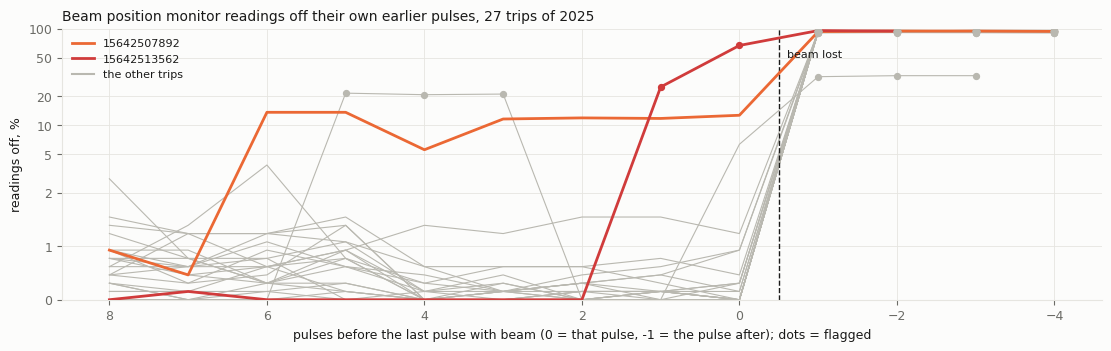

trips flagged at 1 or 0 pulses before the last with beam: 1 of 27; pulse after over 90 % off: 25 of 26


pulses_before_last,0,1,largest
event_id,,,
15642513562,67.0,24.8,67.0
15642507892,12.7,11.7,12.7
15644067268,6.3,0.0,6.3
15642520842,1.2,1.5,1.5
15642519638,0.9,0.6,0.9


In [20]:
bpm = pd.read_parquet("ess_pm/bpm_before_trip.parquet").query("group == 'all' and kind != 'no trip logged' and pulses_before_last <= 8")
flags = bpm.pivot(index="event_id", columns="pulses_before_last", values="flagged")
moved = flags.index[flags[[1, 0]].any(axis=1)].tolist()
steady = bpm[bpm.pulses_before_last >= 0].groupby("event_id").share_out.median().drop(moved).idxmax()
SHOWN = {**{e: CRITICAL for e in moved}, steady: ORANGE}
fig, ax = plt.subplots(figsize=(11, 3.4), constrained_layout=True)
for event_id, rows in bpm.sort_values("pulses_before_last").groupby("event_id"):
    color = SHOWN.get(event_id, GREY)
    ax.plot(rows.pulses_before_last, 100 * rows.share_out, color=color, linewidth=0.8 if color == GREY else 2, label=None if color == GREY else str(event_id), zorder=2 if color == GREY else 3)
    ax.scatter(rows.pulses_before_last[rows.flagged], 100 * rows.share_out[rows.flagged], color=color, s=18, zorder=4)
ax.plot([], [], color=GREY, label="the other trips")
ax.axvline(-0.5, color=INK, linewidth=1, linestyle="--")
ax.text(-0.6, 50, "beam lost", fontsize=8)
ax.invert_xaxis()
ax.set(yscale="symlog", ylim=(0, 100))
ax.set_yticks([0, 1, 2, 5, 10, 20, 50, 100], ["0", "1", "2", "5", "10", "20", "50", "100"])
ax.set_xlabel("pulses before the last pulse with beam (0 = that pulse, -1 = the pulse after); dots = flagged")
ax.set_ylabel("readings off, %")
ax.set_title(f"Beam position monitor readings off their own earlier pulses, {bpm.event_id.nunique()} trips of 2025")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()
after = bpm[bpm.pulses_before_last == -1].share_out
print(f"trips flagged at 1 or 0 pulses before the last with beam: {len(moved)} of {len(flags)}; pulse after over 90 % off: {(after > 0.9).sum()} of {len(after)}")
(100 * bpm[bpm.pulses_before_last.isin([1, 0])].pivot(index="event_id", columns="pulses_before_last", values="share_out")).round(1).assign(largest=lambda d: d.max(axis=1)).sort_values("largest", ascending=False).head(5)

- **Looking for:** where along the linac the horizontal position of the flagged capture leaves its earlier pulses, one pulse before the last and in the last.
- **Data:** `ess_pm/bpm_pulses.parquet`, column `x_distance` (distance to the earlier pulses, in their spreads) per `monitor` and `section`, at 1 and 0 pulses before the last with beam, the flagged capture of the figure above against the median of the other 26 trips.
- **Says:** Capture 15642513562 is 100 to 220 spreads off in the median monitor of every section from the DTL onwards in both pulses, and 1.1 to 1.8 in the MEBT; the other trips sit at 0.7 to 1.2.

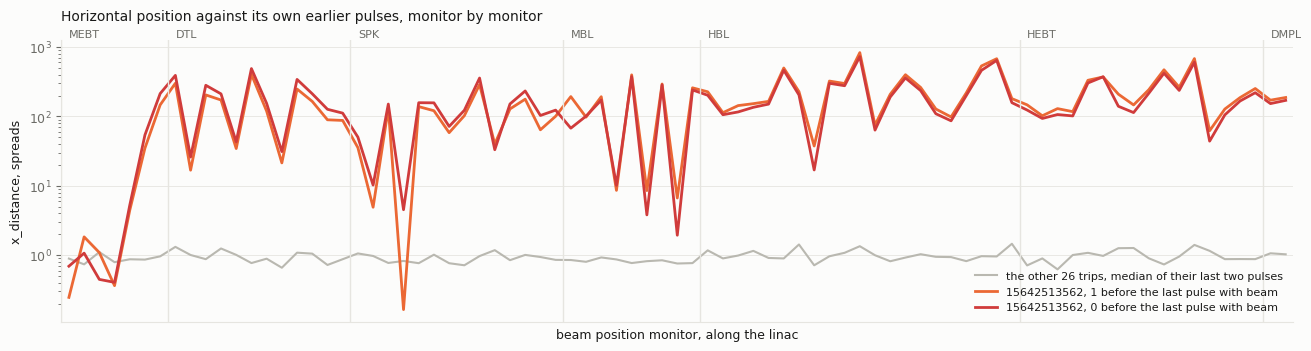

15642513562        other trips     
pulses_before_last           0      1           0    1
section                                               
MEBT                       1.1    1.8         1.1  0.8
DTL                      182.6  141.8         1.1  0.7
SPK                      122.9  101.5         1.1  0.8
MBL                      100.9  192.3         1.1  0.7
HBL                      199.6  218.3         1.1  0.9
HEBT                     153.3  197.9         1.1  0.8
DMPL                     161.6  179.3         1.2  0.8

In [21]:
ORDER = ["MEBT", "DTL", "SPK", "MBL", "HBL", "HEBT", "DMPL"]
wave = pd.read_parquet("ess_pm/bpm_pulses.parquet", columns=["event_id", "monitor", "section", "pulses_before_last", "kind", "x_distance"])
wave = wave[(wave.kind != "no trip logged") & wave.pulses_before_last.isin([1, 0])]
monitors = wave[["monitor", "section"]].drop_duplicates().assign(o=lambda d: d.section.map(ORDER.index)).sort_values(["o", "monitor"])
one_trip, others = wave[wave.event_id == moved[0]], wave[wave.event_id != moved[0]]
fig, ax = plt.subplots(figsize=(13, 3.4), constrained_layout=True)
ax.plot(range(len(monitors)), others.groupby("monitor").x_distance.median().reindex(monitors.monitor), color=GREY, linewidth=1.5, label=f"the other {others.event_id.nunique()} trips, median of their last two pulses")
for back, color in [(1, ORANGE), (0, CRITICAL)]:
    ax.plot(range(len(monitors)), one_trip[one_trip.pulses_before_last == back].set_index("monitor").x_distance.reindex(monitors.monitor), color=color, linewidth=2, label=f"{moved[0]}, {back} before the last pulse with beam")
for section, first in monitors.reset_index(drop=True).groupby("section").apply(lambda g: g.index.min(), include_groups=False).items():
    ax.axvline(first - 0.5, color=GRID, linewidth=1)
    ax.text(first, 1.01, section, fontsize=8, color=MUTED, transform=ax.get_xaxis_transform())
ax.set(yscale="log", xlim=(-0.5, len(monitors) - 0.5), xlabel="beam position monitor, along the linac", ylabel="x_distance, spreads")
ax.set_xticks([])
ax.set_title("Horizontal position against its own earlier pulses, monitor by monitor", pad=14)
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.show()
pd.concat({str(moved[0]): one_trip.groupby(["section", "pulses_before_last"]).x_distance.median().unstack(),
           "other trips": others.groupby(["section", "pulses_before_last"]).x_distance.median().unstack()}, axis=1).reindex(ORDER).round(1)

## 14. Does the shape of the beam pulse change before the beam stops?

- **Looking for:** whether the beam current pulse, divided by its level, moves further from its earlier pulses in the last pulses of a trip capture than in the last pulses of a DD capture.
- **Data:** `ess_pm/beam_shape_pulses.parquet`, column `shape_ratio` (distance to the earlier pulses over what is usual for them), median over the 11 monitors per capture and pulse, 43 PM captures where the beam stops and 30 DD captures; `ess_pm/beam_shape_before.parquet`, columns `limit` (99 % of the PM pulses 5 or more before the stop) and `roc_auc`.
- **Says:** ROC-AUC 0.55, 0.42, 0.58 and 0.46 at 4, 3, 2 and 1 pulses before the stop; 8 of 172 PM pulses are over the limit there, 6 of 170 without the two last pulses that already lost beam, against 5 of 405 earlier pulses (Fisher exact one-sided p 0.07); 0 DD pulses are over it.

In [22]:
shape = pd.read_parquet("ess_pm/beam_shape_pulses.parquet", columns=["capture_type", "event_id", "pulses_before_stop", "beam_stops", "shape_ratio"])
shape = shape[shape.beam_stops == (shape.capture_type == "PM")].dropna(subset="shape_ratio")
capture = shape.groupby(["capture_type", "event_id", "pulses_before_stop"]).shape_ratio.median().reset_index()
before = pd.read_parquet("ess_pm/beam_shape_before.parquet").set_index("pulses_before_stop")
limit = before.limit.iloc[0]
pm_shape = capture[capture.capture_type == "PM"]
earlier, last4 = pm_shape[pm_shape.pulses_before_stop >= 5], pm_shape[pm_shape.pulses_before_stop.between(1, 4)]
# Last pulses more than 10 times the limit: the beam is already cut or lost in them (README).
lost = (last4.pulses_before_stop == 1) & (last4.shape_ratio > 10 * limit)
k, m, k0, m0 = int((last4.shape_ratio[~lost] > limit).sum()), int((~lost).sum()), int((earlier.shape_ratio > limit).sum()), len(earlier)
print(f"PM pulses over the limit: {(last4.shape_ratio > limit).sum()} of {len(last4)} at 1 to 4 before the stop, {k0} of {m0} at 5 or more")
print(f"without the last pulses that lost beam ({', '.join(map(str, last4.event_id[lost]))}): {k} of {m}, Fisher exact one-sided p {stats.fisher_exact([[k, m - k], [k0, m0 - k0]], alternative='greater')[1]:.2f}")

PM pulses over the limit: 8 of 172 at 1 to 4 before the stop, 5 of 405 at 5 or more
without the last pulses that lost beam (16121485108, 16122697297): 6 of 170, Fisher exact one-sided p 0.07


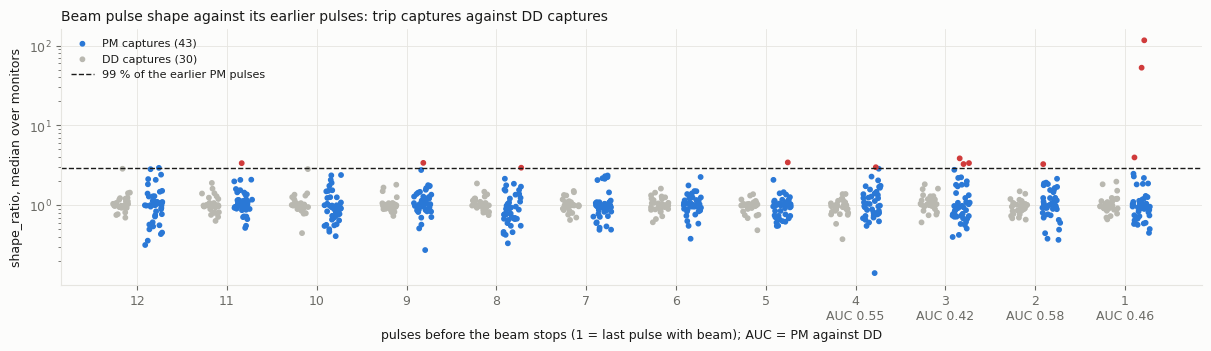

In [23]:
shown = capture[capture.pulses_before_stop.between(1, 12)]
fig, ax = plt.subplots(figsize=(12, 3.4), constrained_layout=True)
for kind, dx, color in [("PM", -0.18, BLUE), ("DD", 0.18, GREY)]:
    rows = shown[shown.capture_type == kind]
    ax.scatter(rows.pulses_before_stop + dx + rng.uniform(-0.1, 0.1, len(rows)), rows.shape_ratio, s=10, color=np.where(rows.shape_ratio > limit, CRITICAL, color),
               label=f"{kind} captures ({rows.event_id.nunique()})")
ax.axhline(limit, color=INK, linewidth=1, linestyle="--", label="99 % of the earlier PM pulses")
ax.set_xticks(range(1, 13), [f"{b}\nAUC {before.roc_auc[b]:.2f}" if b in before.index else str(b) for b in range(1, 13)])
ax.invert_xaxis()
ax.set(yscale="log", xlabel="pulses before the beam stops (1 = last pulse with beam); AUC = PM against DD", ylabel="shape_ratio, median over monitors")
ax.set_title("Beam pulse shape against its earlier pulses: trip captures against DD captures")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

## 15. Does the step the beam leaves in the cavities change before the stop?

- **Looking for:** whether the amplitude and phase step across the beam pulse in each cavity leaves its own earlier pulses in the last pulses of a trip capture.
- **Data:** `ess_pm/beam_step_pulses.parquet`, columns `amp_step_distance`, `phase_step_distance` (out = beyond 99 % of the pulses 5 or more before the stop) and `*_control_distance` (same where no beam passes), share out per capture and pulse, 43 PM and 29 DD captures; `ess_pm/beam_step_before.parquet`, columns `pm_share_out`, `pm_over_limit`, `roc_auc`.
- **Says:** At 4, 3 and 2 pulses before the stop the median trip capture has 0.7 % of its steps out, and 1, 0 and 0 of 43 captures are over the limit; in the last pulse 2 are; PM against DD gives ROC-AUC 0.58 to 0.73 on the beam step and 0.71 where no beam passes.

In [24]:
step = pd.read_parquet("ess_pm/beam_step_pulses.parquet")
step_before = pd.read_parquet("ess_pm/beam_step_before.parquet")
PAIRS = {"beam": ["amp_step_distance", "phase_step_distance"], "control": ["amp_control_distance", "phase_control_distance"]}
normal = step.pulses_before_stop >= 5
share = {}
for pair, cols in PAIRS.items():
    out = (step[cols] > step[cols][normal].quantile(0.99)).where(step[cols].notna())
    s = step[["capture_type", "event_id", "pulses_before_stop"]].assign(out=out.sum(axis=1), n=out.notna().sum(axis=1))
    s = s.groupby(["capture_type", "event_id", "pulses_before_stop"])[["out", "n"]].sum().query("n > 0").reset_index()
    share[pair] = s.assign(share_out=s.out / s.n)
beam_share = share["beam"]
step_limit = beam_share.share_out[(beam_share.capture_type == "PM") & (beam_share.pulses_before_stop >= 5)].quantile(0.99)
step_before.pivot(index="steps", columns="pulses_before_stop", values=["pm_share_out", "pm_over_limit", "roc_auc"]).round(3)

pm_share_out                      pm_over_limit                roc_auc                     
pulses_before_stop            1      2      3      4             1    2    3    4       1      2      3      4
steps                                                                                                         
beam                      0.007  0.007  0.007  0.007           2.0  0.0  0.0  1.0     NaN  0.584  0.731  0.640
control                   0.007  0.006  0.007  0.007           1.0  0.0  0.0  0.0     NaN  0.716  0.709  0.711

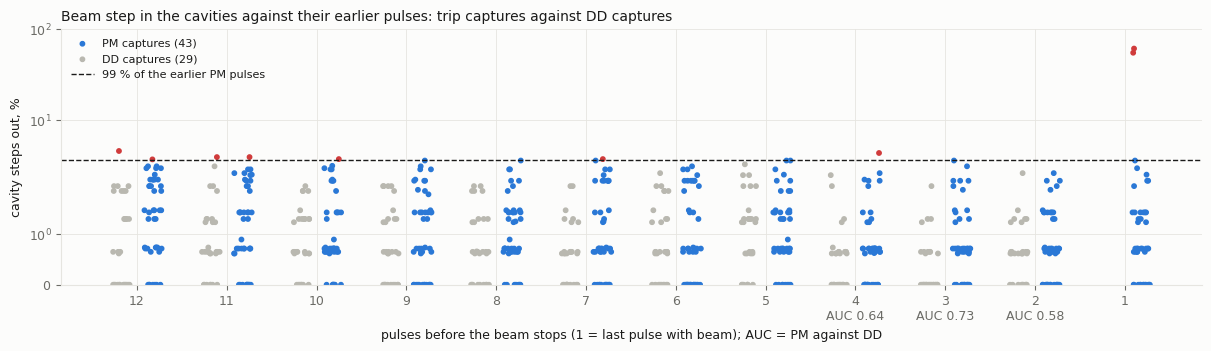

In [25]:
shown = beam_share[beam_share.pulses_before_stop.between(1, 12)]
fig, ax = plt.subplots(figsize=(12, 3.4), constrained_layout=True)
for kind, dx, color in [("PM", -0.18, BLUE), ("DD", 0.18, GREY)]:
    rows = shown[shown.capture_type == kind]
    ax.scatter(rows.pulses_before_stop + dx + rng.uniform(-0.1, 0.1, len(rows)), 100 * rows.share_out, s=10,
               color=np.where(rows.share_out > step_limit, CRITICAL, color), label=f"{kind} captures ({rows.event_id.nunique()})")
ax.axhline(100 * step_limit, color=INK, linewidth=1, linestyle="--", label="99 % of the earlier PM pulses")
auc = step_before[step_before.steps == "beam"].set_index("pulses_before_stop").roc_auc
ax.set_xticks(range(1, 13), [f"{b}\nAUC {auc[b]:.2f}" if b in auc.index and not np.isnan(auc[b]) else str(b) for b in range(1, 13)])
ax.invert_xaxis()
ax.set(yscale="symlog", ylim=(0, 100), xlabel="pulses before the beam stops (1 = last pulse with beam); AUC = PM against DD", ylabel="cavity steps out, %")
ax.set_title("Beam step in the cavities against their earlier pulses: trip captures against DD captures")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

## 16. Does the trip rate depend on the beam current?

- **Looking for:** trips per hour of beam at each level of the beam current read by the first MEBT monitor.
- **Data:** `ess_archiver/trip_current.parquet`, columns `beam_current` (level of the reading, the file gives no unit), `hours_of_beam`, `trips`, `trips_per_hour`; 80 trips where the beam is seen stopping. Error bars: exact Poisson 95 % interval.
- **Says:** 0.73 trips per hour of beam under 10 (60 in 81.8 h), 13.5 at 10 to 40 (7 in 0.52 h), 7.8 over 40 (13 in 1.67 h); the 95 % intervals of the two upper levels lie above that of the lowest.

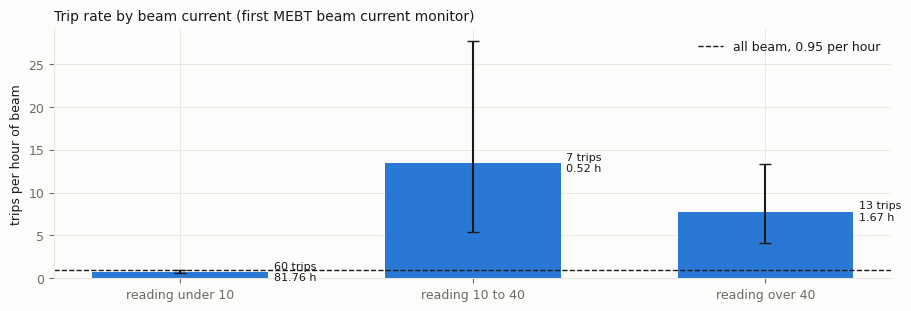

In [26]:
current = pd.read_parquet("ess_archiver/trip_current.parquet")
low = stats.chi2.ppf(0.025, 2 * current.trips) / 2 / current.hours_of_beam
high = stats.chi2.ppf(0.975, 2 * current.trips + 2) / 2 / current.hours_of_beam
overall = current.trips.sum() / current.hours_of_beam.sum()
fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)
x = np.arange(len(current))
ax.bar(x, current.trips_per_hour, 0.6, color=BLUE, yerr=[current.trips_per_hour - low, high - current.trips_per_hour], capsize=4, ecolor=INK)
ax.axhline(overall, color=INK, linewidth=1, linestyle="--", label=f"all beam, {overall:.2f} per hour")
for i, r in enumerate(current.itertuples()):
    ax.text(i + 0.32, r.trips_per_hour, f"{r.trips} trips\n{r.hours_of_beam:.2f} h", fontsize=8, va="center")
ax.set_xticks(x, [f"reading {b}" for b in current.beam_current])
ax.set_ylabel("trips per hour of beam")
ax.set_title("Trip rate by beam current (first MEBT beam current monitor)")
ax.legend(frameon=False)
plt.show()

## 17. Does the trip rate depend on the time since the beam came back?

- **Looking for:** whether trips come sooner after a restart than later, pooled over all beam and within each run.
- **Data:** `ess_archiver/trip_timing.parquet`, kind `all`, columns `span`, `hours_of_beam`, `trips`, `trips_per_hour`; `ess_archiver/trip_timing_runs.parquet`, columns `hours_early`, `hours_late`, `trips_early`, `trips_late` per run (early = first 15 min), 10,000 draws of each run's trips at random moments of its beam time; `ess_archiver/trip_clock.parquet`, column `minutes_since_beam_back`.
- **Says:** Pooled, 2.7 trips per hour under 1 min, 4.6 at 1 to 2 min, down to 0.64 after 60 min; within runs 28 trips fall in the first 15 min where 25.5 are expected, a count reached in 26 % of the draws.

In [27]:
timing = pd.read_parquet("ess_archiver/trip_timing.parquet").query("kind == 'all'")
runs = pd.read_parquet("ess_archiver/trip_timing_runs.parquet")
clock = pd.read_parquet("ess_archiver/trip_clock.parquet")
n = (runs.trips_early + runs.trips_late).to_numpy()
drawn = np.random.default_rng(0).binomial(n, (runs.hours_early / (runs.hours_early + runs.hours_late)).to_numpy(), size=(10_000, len(runs))).sum(axis=1)
seen = int(runs.trips_early.sum())
print(f"trips with a known clock: {clock.minutes_since_beam_back.notna().sum()} of {len(clock)}")
print(f"first 15 min: {seen} trips, {drawn.mean():.1f} expected within runs, {(drawn >= seen).mean():.0%} of the draws reach {seen}")

trips with a known clock: 68 of 80
first 15 min: 28 trips, 25.5 expected within runs, 26% of the draws reach 28


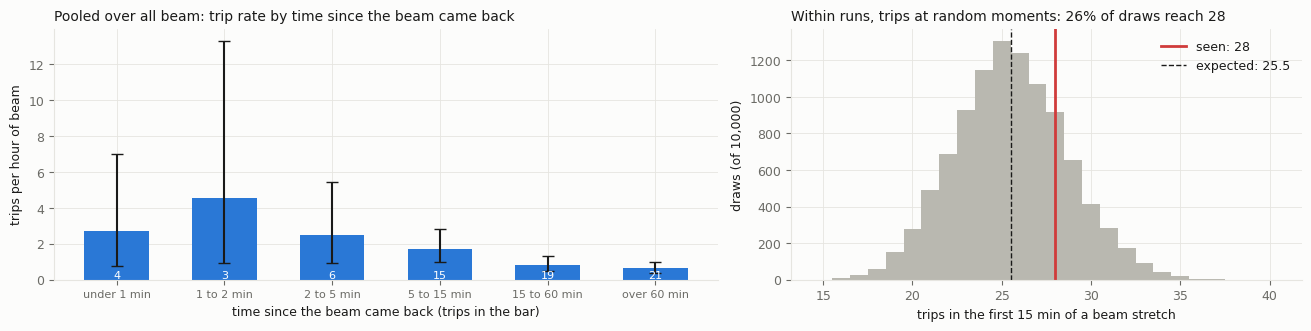

In [28]:
low = stats.chi2.ppf(0.025, 2 * timing.trips) / 2 / timing.hours_of_beam
high = stats.chi2.ppf(0.975, 2 * timing.trips + 2) / 2 / timing.hours_of_beam
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.2), constrained_layout=True, width_ratios=[1.3, 1])
x = np.arange(len(timing))
left.bar(x, timing.trips_per_hour, 0.6, color=BLUE, yerr=[timing.trips_per_hour - low, high - timing.trips_per_hour], capsize=4, ecolor=INK)
for i, r in enumerate(timing.itertuples()):
    left.text(i, 0.1, f"{r.trips}", ha="center", fontsize=8, color="white")
left.set_xticks(x, timing.span, fontsize=8)
left.set(xlabel="time since the beam came back (trips in the bar)", ylabel="trips per hour of beam")
left.set_title("Pooled over all beam: trip rate by time since the beam came back")
right.hist(drawn, bins=np.arange(drawn.min(), drawn.max() + 2) - 0.5, color=GREY)
right.axvline(seen, color=CRITICAL, linewidth=2, label=f"seen: {seen}")
right.axvline(drawn.mean(), color=INK, linewidth=1, linestyle="--", label=f"expected: {drawn.mean():.1f}")
right.set(xlabel="trips in the first 15 min of a beam stretch", ylabel="draws (of 10,000)")
right.set_title(f"Within runs, trips at random moments: {(drawn >= seen).mean():.0%} of draws reach {seen}")
right.legend(frameon=False)
plt.show()

## 18. Do the signals at the trip follow the kind of trip or the year?

- **Looking for:** whether what the Archiver signals see at a trip depends on the kind of trip (RF protection or other) or on the year it happened.
- **Data:** `ess_archiver/pretrip_events.parquet` (47 referenced trips), columns `kind`, `time` (year), `second of the trip | all beam position monitor signals` and `1 to 3 s after | front end RF level`, flagged above `limit` of `ess_archiver/pretrip_summary.parquet`.
- **Says:** Beam position monitors in the second of the trip: 18 of 18 trips of 2025 (17 RF protection) and 6 of 29 of 2026 (0 of 3 RF protection); front end RF level 1 to 3 s after: 1 of 18 against 26 of 29; 17 of the 20 RF protection trips are from 2025.

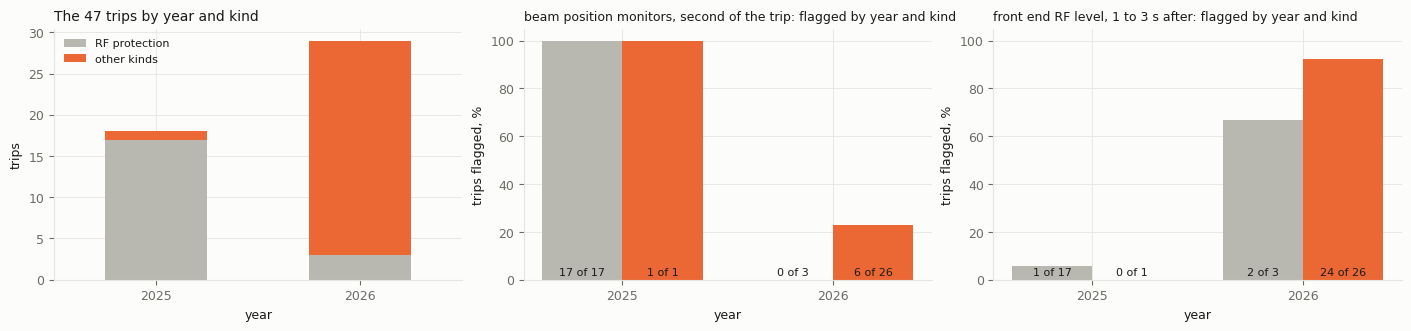

,"beam position monitors, second of the trip","front end RF level, 1 to 3 s after"
year,,
2025,18 of 18,1 of 18
2026,6 of 29,26 of 29


In [29]:
at = events[events.is_trip].assign(year=lambda d: d.time.dt.year, rf=lambda d: np.where(d.kind == "RF protection", "RF protection", "other kinds"))
CASES = {"beam position monitors,\nsecond of the trip": ("second of the trip", "all beam position monitor signals"),
         "front end RF level,\n1 to 3 s after": ("1 to 3 s after", "front end RF level")}
for name, (span, group) in CASES.items():
    at[name] = at[f"{span} | {group}"] > summary[(summary.group == group) & (summary.span == span)].limit.iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), constrained_layout=True)
mix = at.groupby(["year", "rf"]).size().unstack(fill_value=0)
mix.plot.bar(stacked=True, ax=axes[0], color=[GREY, ORANGE], rot=0, legend=False)
axes[0].set(ylabel="trips", xlabel="year")
axes[0].set_title("The 47 trips by year and kind")
axes[0].legend(frameon=False, fontsize=8)
for ax, name in zip(axes[1:], CASES):
    flags = at.groupby(["year", "rf"])[name].agg(["sum", "size"]).unstack()
    for j, (rf, color) in enumerate(zip(mix.columns, [GREY, ORANGE])):
        k, size = flags[("sum", rf)].fillna(0), flags[("size", rf)].fillna(0)
        ax.bar(np.arange(len(flags)) + (j - 0.5) * 0.38, 100 * k / size.replace(0, np.nan), 0.38, color=color)
        for i, (a, b) in enumerate(zip(k, size)):
            ax.text(i + (j - 0.5) * 0.38, 2, f"{a:.0f} of {b:.0f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(flags)), flags.index)
    ax.set(ylim=(0, 105), ylabel="trips flagged, %", xlabel="year")
    ax.set_title(f"{name.replace(chr(10), ' ')}: flagged by year and kind", fontsize=9)
plt.show()
at.groupby("year")[list(CASES)].agg(lambda f: f"{f.sum()} of {len(f)}").rename(columns=lambda c: c.replace("\n", " "))

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

INK, MUTED, SURFACE, GRID, GREY, CRITICAL = "#1a1a19", "#6b6b66", "#fcfcfb", "#e6e5e0", "#b9b8b0", "#d03b3b"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
states = pd.read_parquet("ess_clusters/cluster_states.parquet")
summary = pd.read_parquet("ess_clusters/cluster_summary.parquet")
trips = pd.read_parquet("ess_clusters/cluster_trips.parquet")
moments = pd.read_parquet("ess_clusters/archiver_states.parquet")
arch = pd.read_parquet("ess_clusters/archiver_cluster_summary.parquet")
arch_trips = pd.read_parquet("ess_clusters/archiver_cluster_trips.parquet")

## Clusters of machine states in the captures

**Looking for:** do the pulses 2 to 4 before a trip sit apart from the earlier pulses of the same capture?
**Data:** `ess_clusters/cluster_states.parquet`, 1,152 cycles of 43 PM and 30 DD captures, the 46 `own:` columns
(each cavity feature against the earlier pulses of its capture, median per section, share of cavities off, beam
level, beam step), first two principal components.
**Says:** they sit inside the cloud of earlier pulses, trip and normal captures alike; only pulses after the stop
and a few last pulses lie apart.

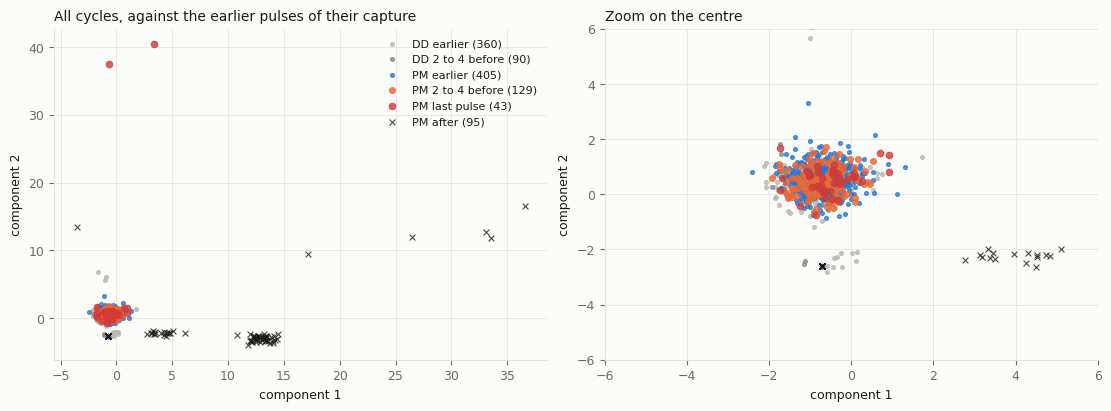

In [31]:
own = [c for c in states.columns if c.startswith("own: ") and not any(m in c for m in ["k-means", "Gaussian", "Ward", "HDBSCAN"])]
x = states[own].clip(-20, 20).fillna(0)
xy = PCA(2, random_state=0).fit_transform((x - x.mean()) / x.std().replace(0, 1))
STYLE = {"DD earlier": (GREY, "o", 8), "DD 2 to 4 before": ("#8a8a83", "o", 8), "PM earlier": ("#2a78d6", "o", 8),
         "PM 2 to 4 before": ("#eb6834", "o", 18), "PM last pulse": (CRITICAL, "o", 22), "PM after": (INK, "x", 18)}
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, lim in ((left, None), (right, 6)):
    for group, (color, marker, size) in STYLE.items():
        on = (states.group == group).to_numpy()
        ax.scatter(xy[on, 0], xy[on, 1], s=size, c=color, marker=marker, label=f"{group} ({on.sum()})", alpha=0.8, linewidths=0.8)
    if lim:
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xlabel("component 1"); ax.set_ylabel("component 2"); ax.grid(color=GRID, linewidth=0.6)
left.set_title("All cycles, against the earlier pulses of their capture", loc="left", fontsize=10)
right.set_title("Zoom on the centre", loc="left", fontsize=10)
left.legend(fontsize=8, frameon=False)
plt.show()

**Looking for:** does any of the 8 clusterings gather the PM pulses 2 to 4 before the stop more than randomly picked
captures do?
**Data:** `ess_clusters/cluster_summary.parquet`, one row per view, method and cluster. PM gain: share of the pulses 2
to 4 before the stop in the cluster minus share of the earlier pulses, averaged over the 43 PM captures. Chance:
share of 1,000 draws, PM and DD swapped between whole captures, reaching the largest PM gain.
**Says:** none does; the lowest chance is 38 %.

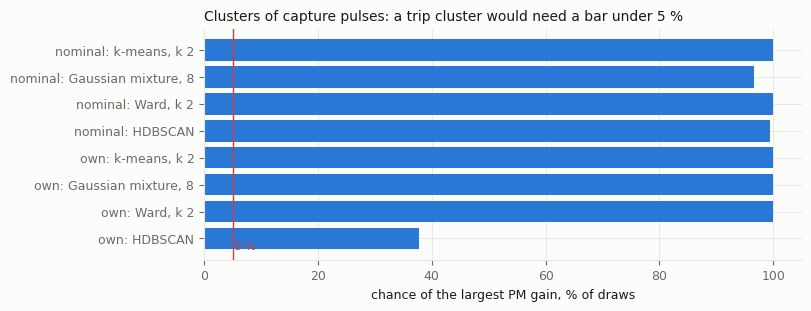

,view,method,largest_gain,chance
0,nominal,"k-means, k 2",0.000,1.000
1,nominal,"Gaussian mixture, 8",0.030,0.967
2,nominal,"Ward, k 2",0.000,1.000
3,nominal,HDBSCAN,0.023,0.995
4,own,"k-means, k 2",0.000,1.000
5,own,"Gaussian mixture, 8",0.046,1.000
6,own,"Ward, k 2",0.000,1.000
7,own,HDBSCAN,0.129,0.378


In [32]:
best = summary.groupby(["view", "method"], sort=False).agg(largest_gain=("PM gain", "max"), chance=("chance", "first")).reset_index()
best["label"] = best.view + ": " + best.method
fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
ax.barh(best.label, 100 * best.chance, color="#2a78d6")
ax.axvline(5, color=CRITICAL, linewidth=1)
ax.text(5.5, len(best) - 0.6, "5 %", color=CRITICAL, fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("chance of the largest PM gain, % of draws"); ax.grid(axis="x", color=GRID, linewidth=0.6)
ax.set_title("Clusters of capture pulses: a trip cluster would need a bar under 5 %", loc="left", fontsize=10)
plt.show()
best[["view", "method", "largest_gain", "chance"]].round(3)

**Looking for:** do the 43 trips form groups by how the machine looks at the stop, and what are the groups?
**Data:** `ess_clusters/cluster_trips.parquet`, one row per PM capture, Gaussian mixture of 6 on the own-view state 2,
1 and 0 pulses from the stop, against `year`, `kind` (interlock log) and `beam_level`.
**Says:** the groups follow the year and the beam current: 16 of the 23 RF protection trips of 2025 in one group, 5
beam instrument trips of 2026 at a median beam level of 24 in another.

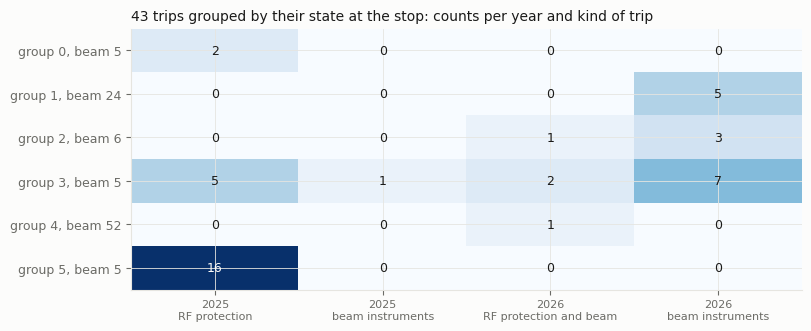

In [33]:
method = "Gaussian mixture, 6"
table = pd.crosstab(trips[method], [trips.year, trips.kind])
fig, ax = plt.subplots(figsize=(8, 3.2), constrained_layout=True)
ax.imshow(table.to_numpy(), cmap="Blues", aspect="auto")
for (i, j), n in np.ndenumerate(table.to_numpy()):
    ax.text(j, i, n, ha="center", va="center", fontsize=9, color=INK if n < 10 else SURFACE)
ax.set_xticks(range(table.shape[1]), [f"{y}\n{k}" for y, k in table.columns], fontsize=8)
level = trips.groupby(method).beam_level.median()
ax.set_yticks(range(table.shape[0]), [f"group {g}, beam {level[g]:.0f}" for g in table.index])
ax.set_title("43 trips grouped by their state at the stop: counts per year and kind of trip", loc="left", fontsize=10)
plt.show()

## Clusters of machine states in the Archiver

**Looking for:** what do the clusters of the slow signals stand for?
**Data:** `ess_clusters/archiver_states.parquet`, 30,162 moments, one per 10 s of the 83.8 hours of beam, HDBSCAN
cluster of each moment (level of 2,175 signals and movement of each group over the minute before), `beam_current`;
the 76 trips of `archiver_cluster_trips.parquet` as red lines. Hours of beam on the x axis, gaps between runs left out.
**Says:** the clusters are periods of operation and the beam current; the outlier group (-1) fills the high current
hours of 2026-06-29 and the minutes after restarts.

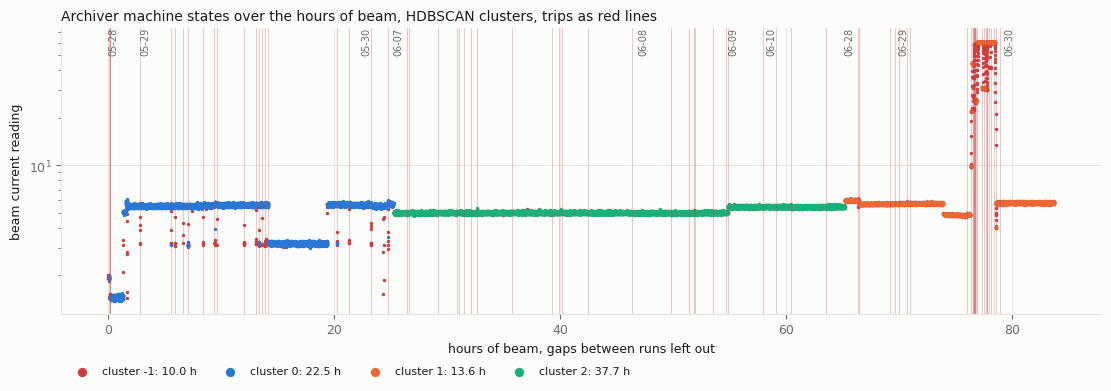

In [34]:
moments = moments.sort_values("time").reset_index(drop=True)
hours = np.arange(len(moments)) * 10 / 3600
fig, ax = plt.subplots(figsize=(11, 3.8), constrained_layout=True)
colors = {-1: CRITICAL, 0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a", 3: "#eda100"}
for c, g in moments.groupby("HDBSCAN"):
    ax.scatter(hours[g.index], g.beam_current, s=2, c=colors.get(c, GREY), label=f"cluster {c}: {len(g) * 10 / 3600:.1f} h")
for t in np.searchsorted(moments.time.to_numpy(), pd.to_datetime(arch_trips.time, utc=True).to_numpy()):
    ax.axvline(hours[min(t, len(hours) - 1)], color=CRITICAL, linewidth=0.4, alpha=0.5)
for i in moments.groupby(moments.time.dt.date).head(1).index:
    ax.text(hours[i], 75, moments.time[i].strftime("%m-%d"), fontsize=7, color=MUTED, rotation=90, va="top")
ax.set_yscale("log"); ax.set_ylabel("beam current reading"); ax.set_xlabel("hours of beam, gaps between runs left out")
ax.legend(fontsize=8, frameon=False, markerscale=4, ncol=4, loc="upper left", bbox_to_anchor=(0, -0.15))
ax.set_title("Archiver machine states over the hours of beam, HDBSCAN clusters, trips as red lines", loc="left", fontsize=10)
plt.show()

**Looking for:** is there a cluster in which trips come more often than its hours at each beam current give, 10 s, 1
min or 5 min before the trip?
**Data:** `ess_clusters/archiver_cluster_summary.parquet`: per method, lead and cluster, `trips` seen and `expected`
(hours at each beam current level times the trip rate of that level, 0.71, 11.9 and 7.25 per hour). Chance: share of
2,000 draws of each trip at a random moment of the same run, beam current level and time since the beam came back.
**Says:** 1 of 9 tests is at about 1 % (HDBSCAN outliers 10 s before: 25 trips where 16.5 are expected), none at 1 or
5 min. One of 9 tests that low is what chance gives about 1 time in 10.

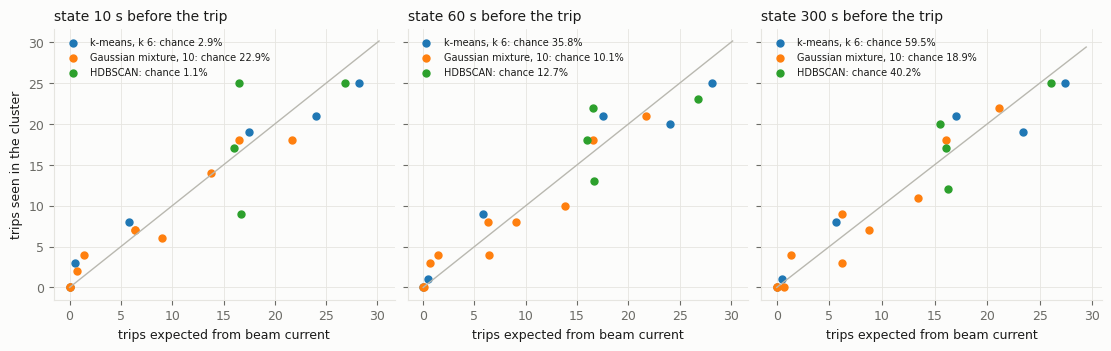

method,"k-means, k 6","Gaussian mixture, 10",HDBSCAN
lead_s,,,
10,0.030,0.229,0.012
60,0.358,0.101,0.127
300,0.594,0.188,0.402


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True, constrained_layout=True)
for ax, (lead, g) in zip(axes, arch.groupby("lead_s")):
    for method, m in g.groupby("method", sort=False):
        ax.scatter(m.expected, m.trips, s=25, label=f"{method}: chance {m.chance.iloc[0]:.1%}")
    top = max(g.trips.max(), g.expected.max()) + 2
    ax.plot([0, top], [0, top], color=GREY, linewidth=1)
    ax.set_title(f"state {lead} s before the trip", loc="left", fontsize=10)
    ax.set_xlabel("trips expected from beam current"); ax.grid(color=GRID, linewidth=0.6)
    ax.legend(fontsize=7, frameon=False)
axes[0].set_ylabel("trips seen in the cluster")
plt.show()
arch.groupby(["lead_s", "method"], sort=False).chance.first().unstack().round(3)